# Predicción del Tiempo de Entrega en Comercio Electrónico
**Proyecto Semestral · Análisis de Negocios (IND-163C) · 2026-02 · Grupo 4**

| Integrante | ROL | Rol principal en el proyecto |
|---|---|---|
| Lautaro Morales | 202160640-8 | *(completar)* |
| Vicente Vergara | 202160591-6 | *(completar)* |
| Joaquín Valero | 202160609-2 | *(completar)* |
| Maximiliano Espinosa | 202160605-k | *(completar)* |

**Problema de negocio.** Una plataforma de comercio electrónico quiere estimar, **en el momento en que el cliente realiza la compra**, cuántos días tardará el pedido en llegar. Una estimación precisa permite comunicar plazos realistas, planificar la logística y detectar con anticipación los pedidos con riesgo de demora.

**Tipo de problema.** Regresión supervisada. La variable objetivo es `DELIVERY_TIME_DAYS`: los días transcurridos entre la compra y la entrega al cliente.

**Resumen de resultados**
- **Dimensión crítica identificada: fuga de información (data leakage).** Unas 15 columnas solo existen después de la compra. Con ellas, el R² llega a 0,92, pero el modelo sería inutilizable en la práctica. Se excluyen todas (§2.3 y §7.2).
- **Modelo final: Gradient Boosting** (220 árboles, `learning_rate` = 0,05, `max_depth` = 4, `min_samples_leaf` = 20, `subsample` = 0,8).
- **Test:** MAE = 4,51 días · RMSE = 6,75 · R² = 0,36 · sesgo = −0,19 días.
- **K-Fold (K = 5) en Train:** MAE = 4,62 ± 0,04 días.
- **Puntos de comparación:** la estimación actual de la plataforma tiene un MAE de 12,5 días y predecir siempre el promedio, 6,1 días.

**Estructura del notebook**
1. Configuración y carga de datos
2. Comprensión del dataset: unidad de análisis, variable objetivo y clasificación de variables
3. Limpieza de datos
4. Análisis exploratorio (EDA)
5. Selección de variables y preprocesamiento
6. Train/Test Split
7. Decisiones previas validadas con datos: fuga de información, tratamiento del target y variables candidatas
8. Modelos candidatos e hiperparámetros (Elastic Net, Random Forest, Gradient Boosting)
9. Evaluación en Test, comparación y selección del modelo final
10. K-Fold Cross Validation (K = 5) del modelo seleccionado
11. Exportación del modelo para la aplicación web
12. Conclusiones

## 1. Configuración y carga de datos

Fijamos una semilla (`SEMILLA = 42`) en todos los procesos aleatorios para que los resultados sean reproducibles.

La ingeniería de variables está en el archivo `utils/features.py` del repositorio. Lo importamos desde aquí y la aplicación web importa **el mismo archivo**, lo que garantiza que el modelo recibe exactamente las mismas transformaciones en el entrenamiento y en la app.

In [1]:
import os
import sys
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import sklearn
import joblib
from joblib import Parallel, delayed

from sklearn.base import clone
from sklearn.model_selection import train_test_split, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

# Carpeta raíz del repositorio (funciona si el notebook se ejecuta desde la raíz o desde notebooks/)
RAIZ = Path.cwd() if (Path.cwd() / "utils").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))
# Los procesos paralelos de joblib también necesitan encontrar la carpeta utils/
os.environ["PYTHONPATH"] = str(RAIZ) + os.pathsep + os.environ.get("PYTHONPATH", "")

from utils.features import (construir_variables, ENTRADAS, ENTRADAS_NUMERICAS, ENTRADAS_CATEGORICAS,
                            VARIABLES_NUMERICAS, VARIABLES_CATEGORICAS, TARGET, COL_FECHA_COMPRA)

SEMILLA = 42
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 200)

# Paleta y estilo de gráficos
AZUL, NARANJO, VERDE, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
sns.set_theme(style="whitegrid", rc={"axes.edgecolor": "#cfcfcb", "grid.color": "#ececea",
                                      "axes.titleweight": "bold", "axes.titlesize": 12})

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__}")

Python 3.13.16 | pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1


In [2]:
RUTA_DATOS = RAIZ / "data" / "Dataset_Ordenes_Comp E-Commerce.xlsx"
df_raw = pd.read_excel(RUTA_DATOS, sheet_name="Dataset_Proyecto")
readme = pd.read_excel(RUTA_DATOS, sheet_name="Fuentes_README")
print(f"Dimensiones: {df_raw.shape[0]:,} filas x {df_raw.shape[1]} columnas")
df_raw.head(3)

Dimensiones: 7,000 filas x 70 columnas


,order_id,customer_id,customer_unique_id,order_status,customer_zip_code_prefix,customer_city,customer_state,customer_geo_lat,customer_geo_lng,customer_geo_points,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,purchase_year,purchase_month,purchase_dayofweek,purchase_hour,approval_delay_hours,carrier_dispatch_delay_hours,estimated_delivery_days,DELIVERY_TIME_DAYS,delivery_vs_estimate_days,LATE_DELIVERY_FLAG,order_item_count,unique_product_count,unique_seller_count,first_product_id,first_seller_id,first_product_category_pt,first_product_category_en,unique_product_categories,total_item_price,avg_item_price,max_item_price,total_freight_value,avg_freight_value,total_products_plus_freight,freight_ratio,avg_product_weight_g,avg_product_length_cm,avg_product_height_cm,avg_product_width_cm,avg_product_volume_cm3,avg_product_name_length,avg_product_description_length,avg_product_photos_qty,product_items_missing_physical_specs,shipping_limit_date_max,first_seller_zip_code_prefix,first_seller_city,first_seller_state,first_seller_geo_lat,first_seller_geo_lng,customer_first_seller_distance_km,payment_record_count,payment_type_primary,payment_method_count,payment_max_installments,payment_total_value,payment_vs_order_value_gap,review_count,review_score_avg,review_score_min,review_id_first,review_creation_date_first,review_answer_timestamp_first,review_title_length,review_message_length
0,286f5f216f1c33c728468b8049169006,1dd626464ca63eff653435fa35ed589b,867baeb0278332d0ec8a169c3d4b1486,delivered,7600,mairipora,SP,-23.329722,-46.597122,587.0,2017-10-09 23:07:52,2017-10-11 03:14:34,2017-10-23 22:47:46,2017-10-26 18:07:50,2017-10-30 00:00:00,2017,10,0,23,28.111667,307.553333,20.036204,16.791644,-3.244560,0.0,1.0,1.0,1.0,f4f4debbcfcafe6858d1e37a1f6e436e,7c67e1448b00f6e969d365cea6b010ab,moveis_escritorio,office_furniture,1.0,159.94,159.94,159.94,35.28,35.28,195.22,0.180719,13867.0,101.0,8.0,57.0,46056.0,33.0,1190.0,1.0,0.0,2017-10-26 04:14:34,8577.0,itaquaquecetuba,SP,-23.486111,-46.366721,29.243309,1.0,boleto,1.0,1.0,195.22,0.0,1.0,3.0,3.0,d958e9e4a8a0de6204ef52daee1a6d55,2017-10-27 00:00:00,2017-10-28 08:00:54,NaN,NaN
1,4bf9917773b973b77d02d12241387084,3f6835f041140f84ab67567c59aa5e61,749e46453d6ab7071310a6aa11846ac5,delivered,9280,santo andre,SP,-23.640144,-46.516159,214.0,2017-10-15 20:32:15,2017-10-15 20:49:21,2017-10-16 22:52:15,2017-10-24 00:45:29,2017-11-08 00:00:00,2017,10,6,20,0.285000,26.048333,23.144271,8.175856,-14.968414,0.0,1.0,1.0,1.0,6cdd53843498f92890544667809f1595,ccc4bbb5f32a6ab2b7066a4130f114e3,beleza_saude,health_beauty,1.0,349.90,349.90,349.90,17.21,17.21,367.11,0.046880,900.0,25.0,12.0,38.0,11400.0,51.0,625.0,1.0,0.0,2017-10-24 20:49:21,80310.0,curitiba,PR,-25.456934,-49.309455,347.301485,1.0,credit_card,1.0,8.0,367.11,0.0,1.0,1.0,1.0,146dce4479e8137b0c1287d4963b1340,2017-10-25 00:00:00,2017-10-25 12:49:55,NaN,27.0
2,b48c1dd4cb4c98e4dceeb753c952c961,f59bcf02757dd0a656acd021758b6b0f,82e64e3af13810067a2c33a1372580be,delivered,48540,jeremoabo,BA,-9.953806,-38.671437,73.0,2018-03-11 22:48:32,2018-03-11 23:00:29,2018-03-13 23:11:38,2018-04-04 23:54:47,2018-04-11 00:00:00,2018,3,6,22,0.199167,48.185833,30.049630,24.046007,-6.003623,0.0,1.0,1.0,1.0,f4fb1fcc46bdd61b314fe0292175e5db,12b9676b00f60f3b700e83af21824c0e,cool_stuff,cool_stuff,1.0,199.00,199.00,199.00,63.42,63.42,262.42,0.241674,850.0,33.0,44.0,19.0,27588.0,53.0,270.0,1.0,0.0,2018-03-22 23:00:29,95780.0,montenegro,RS,-29.687804,-51.467964,2565.411453,1.0,credit_card,1.0,8.0,262.42,0.0,1.0,3.0,3.0,756b9640119efc87a3edcb18eaeecea5,2018-04-05 00:00:00,2018-04-09 09:20:05,NaN,29.0


El archivo trae una segunda hoja (`Fuentes_README`) con el contexto del dataset. Destacamos dos párrafos porque guían el proyecto: el problema de negocio y la advertencia sobre la **fuga de información (data leakage)**.

In [3]:
for _, fila in readme.iloc[[3, 4]].iterrows():
    print(f"■ {fila.iloc[0]}\n{fila.iloc[1]}\n")

■ Problema de negocio
Una empresa de comercio electrónico busca mejorar la gestión de sus entregas y reducir la incertidumbre asociada a los tiempos que transcurren entre la realización de una compra y la recepción del pedido por parte del cliente.

El objetivo es desarrollar un modelo de regresión capaz de estimar el tiempo real de entrega de una orden, utilizando información disponible sobre la compra, los productos involucrados, las características logísticas, la ubicación del cliente y del vendedor y los antecedentes asociados al pago.

Una predicción más precisa del tiempo de entrega podría apoyar decisiones relacionadas con planificación logística, priorización de pedidos, comunicación de plazos al cliente y detección anticipada de órdenes con mayor riesgo de presentar tiempos de entrega elevados.

Uno de los principales desafíos del proyecto consiste en determinar qué variables pueden utilizarse legítimamente al momento de generar la predicción, evitando incorporar información q

## 2. Comprensión del dataset

### 2.1 Unidad de análisis
Antes de modelar hay que saber **qué representa cada fila**. Si una orden apareciera repetida (por ejemplo, una fila por producto), la misma orden podría quedar en Train y en Test a la vez, y el modelo se evaluaría con datos que ya vio.

In [4]:
print("¿order_id es único?         ", df_raw["order_id"].is_unique)
print("Órdenes distintas:          ", df_raw["order_id"].nunique())
print("Clientes distintos:         ", df_raw["customer_unique_id"].nunique())
print("Filas duplicadas exactas:   ", df_raw.duplicated().sum())
print("Órdenes con más de 1 ítem:  ", int((df_raw["order_item_count"] > 1).sum()))

¿order_id es único?          True
Órdenes distintas:           7000
Clientes distintos:          6983
Filas duplicadas exactas:    0
Órdenes con más de 1 ítem:   708


**Cada fila es una orden de compra** (7.000 órdenes únicas, sin duplicados). Las órdenes con varios productos ya vienen **agregadas** en una sola fila (conteos, sumas y promedios de los ítems), así que no hay que agrupar. Hay 17 clientes con más de una orden; no es un problema, porque la unidad es la orden y cada compra es un evento distinto.

### 2.2 Variable objetivo
`DELIVERY_TIME_DAYS` debería ser la diferencia entre la fecha de entrega y la fecha de compra. Lo verificamos recalculándola.

In [5]:
COLUMNAS_FECHA = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
                  "order_delivered_customer_date", "order_estimated_delivery_date", "shipping_limit_date_max",
                  "review_creation_date_first", "review_answer_timestamp_first"]
for c in COLUMNAS_FECHA:
    df_raw[c] = pd.to_datetime(df_raw[c], errors="coerce")

recalculado = (df_raw["order_delivered_customer_date"] - df_raw["order_purchase_timestamp"]).dt.total_seconds() / 86400
print("Diferencia máxima entre el target y nuestro cálculo:", round((recalculado - df_raw[TARGET]).abs().max(), 6), "días")
print("Órdenes sin target:", df_raw[TARGET].isna().sum())

Diferencia máxima entre el target y nuestro cálculo: 1e-06 días
Órdenes sin target: 209


El target coincide exactamente con *fecha de entrega − fecha de compra*, medido en días con decimales. Hay 209 órdenes sin target (las revisamos en la limpieza).

### 2.3 Clasificación de las 70 variables según **cuándo se conocen**
El modelo se usará **en el momento de la compra**, así que solo puede usar información disponible en ese instante. Clasificamos cada columna del dataset y verificamos con código que ninguna quede sin clasificar.

In [6]:
clasificacion = {
    "Identificador (sin valor predictivo generalizable)": [
        "order_id", "customer_id", "customer_unique_id", "first_product_id", "first_seller_id", "review_id_first"],
    "Variable objetivo y su fecha de origen": [
        "DELIVERY_TIME_DAYS", "order_delivered_customer_date"],
    "FUGA: derivada del target": [
        "delivery_vs_estimate_days", "LATE_DELIVERY_FLAG"],
    "FUGA: se genera durante el proceso logístico (después de comprar)": [
        "order_status", "order_approved_at", "approval_delay_hours", "order_delivered_carrier_date",
        "carrier_dispatch_delay_hours", "shipping_limit_date_max"],
    "FUGA: se genera después de la entrega (reseña del cliente)": [
        "review_count", "review_score_avg", "review_score_min", "review_creation_date_first",
        "review_answer_timestamp_first", "review_title_length", "review_message_length"],
    "Disponible al comprar → USADA en el modelo": ENTRADAS,
    "Disponible al comprar → descartada por redundante (se recalcula o duplica otra)": [
        "order_estimated_delivery_date", "purchase_month", "purchase_dayofweek", "purchase_hour",
        "customer_first_seller_distance_km", "freight_ratio",
        "avg_item_price", "max_item_price", "avg_freight_value", "total_products_plus_freight", "payment_total_value",
        "payment_vs_order_value_gap", "payment_record_count", "payment_method_count", "unique_product_count",
        "unique_product_categories", "first_product_category_pt", "avg_product_length_cm", "avg_product_height_cm",
        "avg_product_width_cm"],
    "Disponible al comprar → descartada por bajo aporte o constante": [
        "customer_geo_points", "avg_product_name_length", "avg_product_description_length", "avg_product_photos_qty",
        "product_items_missing_physical_specs"],
    "Disponible al comprar → reemplazada por coordenadas (texto o código postal)": [
        "customer_zip_code_prefix", "customer_city", "first_seller_zip_code_prefix", "first_seller_city"],
    "Disponible al comprar → descartada porque no generaliza a fechas futuras": [
        "purchase_year"],
}
asignadas = [c for cols in clasificacion.values() for c in cols]
assert len(asignadas) == len(set(asignadas)), "Hay columnas clasificadas dos veces"
assert set(asignadas) == set(df_raw.columns), f"Sin clasificar: {set(df_raw.columns) - set(asignadas)}"

tabla_clasif = pd.DataFrame([{"Grupo": g, "N° columnas": len(c), "Columnas": ", ".join(c)} for g, c in clasificacion.items()])
print(f"Las {len(asignadas)} columnas quedaron clasificadas exactamente una vez.")
display(tabla_clasif.style.hide(axis="index").set_properties(subset=["Columnas"], **{"text-align": "left"}))

Las 70 columnas quedaron clasificadas exactamente una vez.


Grupo,N° columnas,Columnas
Identificador (sin valor predictivo generalizable),6,"order_id, customer_id, customer_unique_id, first_product_id, first_seller_id, review_id_first"
Variable objetivo y su fecha de origen,2,"DELIVERY_TIME_DAYS, order_delivered_customer_date"
FUGA: derivada del target,2,"delivery_vs_estimate_days, LATE_DELIVERY_FLAG"
FUGA: se genera durante el proceso logístico (después de comprar),6,"order_status, order_approved_at, approval_delay_hours, order_delivered_carrier_date, carrier_dispatch_delay_hours, shipping_limit_date_max"
FUGA: se genera después de la entrega (reseña del cliente),7,"review_count, review_score_avg, review_score_min, review_creation_date_first, review_answer_timestamp_first, review_title_length, review_message_length"
Disponible al comprar → USADA en el modelo,17,"order_purchase_timestamp, customer_geo_lat, customer_geo_lng, first_seller_geo_lat, first_seller_geo_lng, estimated_delivery_days, order_item_count, unique_seller_count, total_item_price, total_freight_value, avg_product_weight_g, avg_product_volume_cm3, payment_max_installments, customer_state, first_seller_state, payment_type_primary, first_product_category_en"
Disponible al comprar → descartada por redundante (se recalcula o duplica otra),20,"order_estimated_delivery_date, purchase_month, purchase_dayofweek, purchase_hour, customer_first_seller_distance_km, freight_ratio, avg_item_price, max_item_price, avg_freight_value, total_products_plus_freight, payment_total_value, payment_vs_order_value_gap, payment_record_count, payment_method_count, unique_product_count, unique_product_categories, first_product_category_pt, avg_product_length_cm, avg_product_height_cm, avg_product_width_cm"
Disponible al comprar → descartada por bajo aporte o constante,5,"customer_geo_points, avg_product_name_length, avg_product_description_length, avg_product_photos_qty, product_items_missing_physical_specs"
Disponible al comprar → reemplazada por coordenadas (texto o código postal),4,"customer_zip_code_prefix, customer_city, first_seller_zip_code_prefix, first_seller_city"
Disponible al comprar → descartada porque no generaliza a fechas futuras,1,purchase_year


**Cómo distinguimos lo que se conoce al comprar:**
- **Se conocen al comprar:** dónde está el cliente y el vendedor, qué productos compra (precio, flete, peso, volumen, categoría), cómo paga y cuándo compra. También `estimated_delivery_days`: según la descripción del dataset, la fecha estimada **se informa al cliente en el momento de la compra**, así que es legítima y además nos sirve como benchmark de negocio.
- **No se conocen al comprar (fuga):** la aprobación del pago y su demora, la fecha en que el vendedor entrega al transportista, la fecha límite de despacho (se fija al aprobar el pago), el estado final de la orden, el atraso respecto de la estimación y todas las variables de la reseña (el cliente la escribe después de recibir el pedido).
- `estimated_delivery_days` se calcula como *fecha estimada − fecha de compra*, es decir, usa la fecha estimada, que es conocida al comprar; no usa la entrega real.

En la sección 7.2 mostramos con números qué pasaría si usáramos las variables con fuga.

## 3. Limpieza de datos

### 3.1 Estado de la orden y órdenes sin target

In [7]:
resumen_estado = (df_raw.groupby("order_status")
                  .agg(ordenes=("order_id", "size"), con_target=(TARGET, lambda s: s.notna().sum()))
                  .sort_values("ordenes", ascending=False))
resumen_estado

,ordenes,con_target
order_status,,
delivered,6792,6791
shipped,88,0
unavailable,40,0
canceled,37,0
processing,28,0
invoiced,13,0
created,1,0
approved,1,0


- Solo las órdenes **entregadas** (`delivered`) tienen target. Las canceladas o no disponibles nunca se entregaron, y las que están en tránsito (`shipped`, `processing`, `invoiced`…) no sabemos cuándo llegarán. Ninguna sirve para aprender el tiempo de entrega.
- Hay **1 orden marcada como entregada pero sin fecha de entrega**; también se excluye porque no tiene target.
- Resultado: trabajamos con **6.791 órdenes entregadas** (97% del total).
- `order_status` no se usa como predictor: después de filtrar es constante y, además, no se conoce al momento de comprar.

In [8]:
df = df_raw[df_raw[TARGET].notna()].copy().reset_index(drop=True)
print("Órdenes para modelar:", len(df), "| estados presentes:", df["order_status"].unique().tolist())

Órdenes para modelar: 6791 | estados presentes: ['delivered']


### 3.2 Inconsistencias y valores faltantes

In [9]:
inconsistencias = pd.Series({
    "Entregada al transportista ANTES de la compra": (df["order_delivered_carrier_date"] < df["order_purchase_timestamp"]).sum(),
    "Entregada al cliente ANTES que al transportista": (df["order_delivered_customer_date"] < df["order_delivered_carrier_date"]).sum(),
    "Precio total <= 0": (df["total_item_price"] <= 0).sum(),
    "Peso <= 0": (df["avg_product_weight_g"] <= 0).sum(),
    "Estimación de la plataforma <= 0 días": (df["estimated_delivery_days"] <= 0).sum(),
    "Target <= 0 días": (df[TARGET] <= 0).sum(),
}, name="Registros")
display(inconsistencias.to_frame())

faltantes = df[ENTRADAS].isna().sum()
faltantes = faltantes[faltantes > 0].to_frame("Faltantes")
faltantes["% del total"] = (100 * faltantes["Faltantes"] / len(df)).round(2)
faltantes

,Registros
Entregada al transportista ANTES de la compra,9
Entregada al cliente ANTES que al transportista,1
Precio total <= 0,0
Peso <= 0,0
Estimación de la plataforma <= 0 días,0
Target <= 0 días,0


,Faltantes,% del total
customer_geo_lat,18,0.27
customer_geo_lng,18,0.27
first_seller_geo_lat,11,0.16
first_seller_geo_lng,11,0.16
payment_max_installments,1,0.01
payment_type_primary,1,0.01
first_product_category_en,94,1.38


**Decisiones de limpieza:**
- Las fechas inconsistentes (9 órdenes "despachadas antes de comprar" y 1 "entregada al cliente antes que al transportista") solo afectan a columnas que **igual excluimos por fuga**. No alteran el target ni las variables del modelo, así que no eliminamos esas órdenes.
- No hay precios, pesos, estimaciones ni targets negativos o nulos.
- Los faltantes en las variables que usaremos son pocos (como máximo 1,4% en la categoría del producto) y **no se eliminan filas**: se imputan dentro del Pipeline (mediana para numéricas y moda para categóricas), y el imputador se ajusta **solo con Train**. Eliminar filas haría que la app no pudiera responder cuando falta un dato.
- Las coordenadas faltantes (18 clientes y 11 vendedores) hacen que la distancia quede vacía en 29 órdenes; también se imputa en el Pipeline.

## 4. Análisis exploratorio de datos (EDA)

Para el EDA calculamos las variables derivadas (distancia, ratio de flete, mes, día y hora de compra) con la misma función que usará el modelo.

In [10]:
eda = pd.concat([construir_variables(df[ENTRADAS]), df[[TARGET, COL_FECHA_COMPRA]]], axis=1)
y_all = df[TARGET]
print(y_all.describe(percentiles=[.01, .05, .25, .5, .75, .9, .95, .99]).round(2).to_string())
print(f"\nAsimetría (skewness): {y_all.skew():.2f}")

count    6791.00
mean       12.27
std         8.81
min         1.02
1%          1.84
5%          3.03
25%         6.60
50%        10.18
75%        15.25
90%        22.84
95%        28.22
99%        43.29
max       167.60

Asimetría (skewness): 3.01


### 4.1 Distribución de la variable objetivo

Atípicos según regla IQR (> 28.2 días): 338 órdenes (5.0%)
Órdenes con más de 60 días: 13 | máximo: 167.6 días


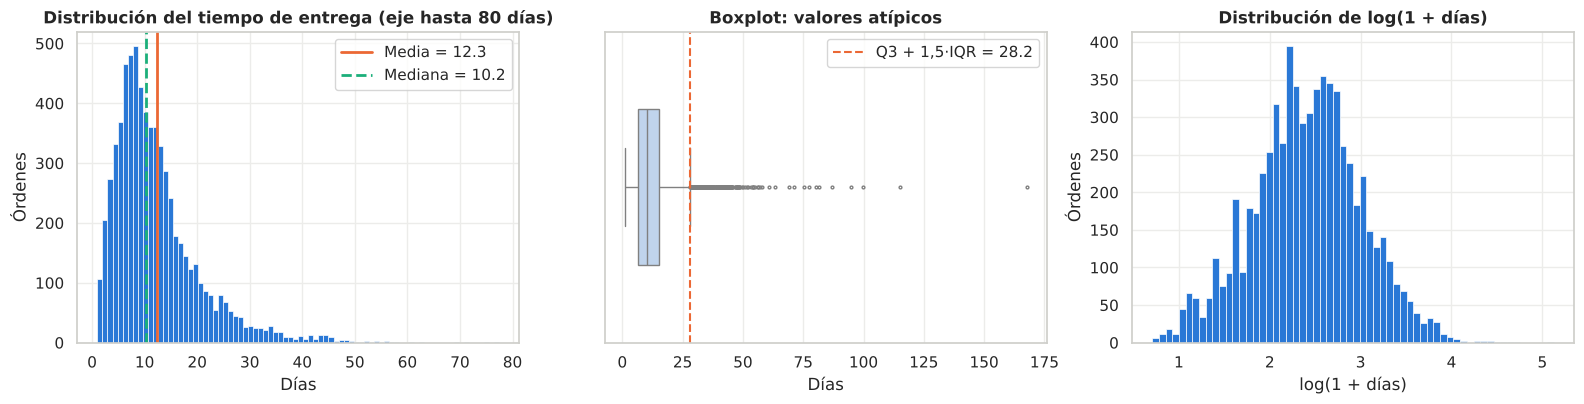

In [11]:
q1, q3 = y_all.quantile([.25, .75])
limite_iqr = q3 + 1.5 * (q3 - q1)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].hist(y_all[y_all <= 80], bins=80, color=AZUL, edgecolor="white", linewidth=0.5)
ax[0].axvline(y_all.mean(), color=NARANJO, lw=2, label=f"Media = {y_all.mean():.1f}")
ax[0].axvline(y_all.median(), color=VERDE, lw=2, ls="--", label=f"Mediana = {y_all.median():.1f}")
ax[0].set(title="Distribución del tiempo de entrega (eje hasta 80 días)", xlabel="Días", ylabel="Órdenes"); ax[0].legend()
sns.boxplot(x=y_all, ax=ax[1], color="#b9d3f3", width=0.5, fliersize=2, linewidth=1)
ax[1].axvline(limite_iqr, color=NARANJO, ls="--", lw=1.5, label=f"Q3 + 1,5·IQR = {limite_iqr:.1f}")
ax[1].set(title="Boxplot: valores atípicos", xlabel="Días"); ax[1].legend()
ax[2].hist(np.log1p(y_all), bins=60, color=AZUL, edgecolor="white", linewidth=0.5)
ax[2].set(title="Distribución de log(1 + días)", xlabel="log(1 + días)", ylabel="Órdenes")
plt.tight_layout(); plt.show()
print(f"Atípicos según regla IQR (> {limite_iqr:.1f} días): {(y_all > limite_iqr).sum()} órdenes ({100*(y_all > limite_iqr).mean():.1f}%)")
print(f"Órdenes con más de 60 días: {(y_all > 60).sum()} | máximo: {y_all.max():.1f} días")

**Hallazgos:**
- La mitad de los pedidos llega en 10,2 días o menos y el promedio es 12,3 días. La distribución es **asimétrica a la derecha** (skewness 3,0), con una cola larga de pedidos muy demorados.
- Según la regla IQR hay 338 atípicos (5,0%), con valores extremos de hasta 167,6 días (13 órdenes superan los 60 días). Esos pedidos son reales (no son errores de digitación), pero corresponden a eventos excepcionales que difícilmente se pueden anticipar con la información de la compra.
- **Consecuencias para el modelamiento:** (1) en una pérdida cuadrática, unos pocos casos extremos pueden dominar el ajuste; (2) MAE y RMSE van a contar historias distintas; (3) en logaritmo la distribución es casi simétrica, así que vale la pena evaluar esa transformación. Las tres opciones se comparan con datos en la sección 7.3.

### 4.2 Benchmark de negocio: la estimación que hoy entrega la plataforma

Estimación promedio de la plataforma: 23.7 días | tiempo real promedio: 12.3 días
MAE de la estimación de la plataforma: 12.75 días
Correlación estimación-real: 0.39
Pedidos que llegan después de la fecha estimada: 7.8%


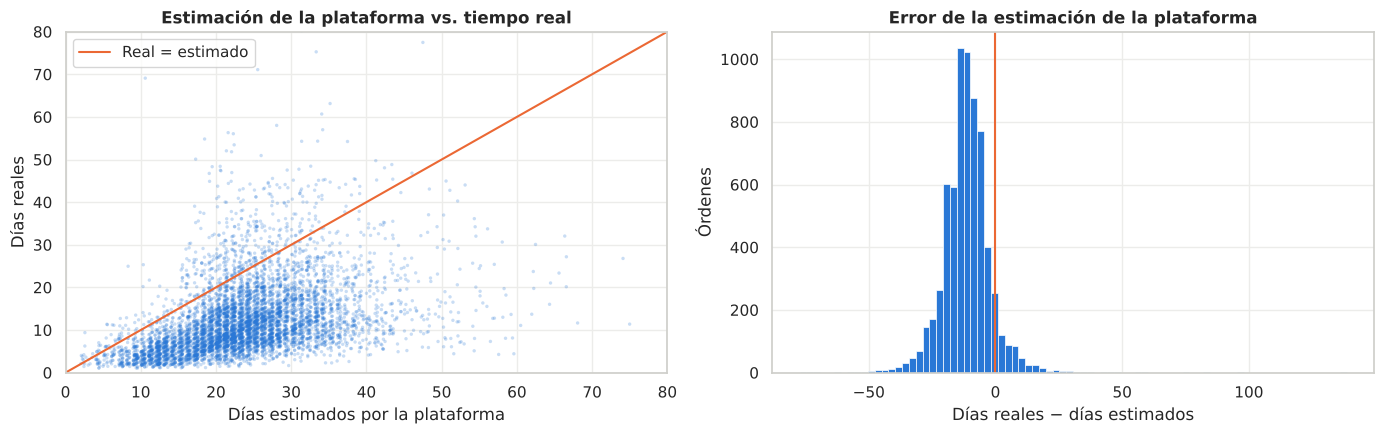

In [12]:
estimacion = df["estimated_delivery_days"]
error_plataforma = y_all - estimacion
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].scatter(estimacion, y_all, s=6, alpha=0.25, color=AZUL, edgecolors="none")
lim = [0, 80]
ax[0].plot(lim, lim, color=NARANJO, lw=1.5, label="Real = estimado")
ax[0].set(xlim=lim, ylim=lim, xlabel="Días estimados por la plataforma", ylabel="Días reales", title="Estimación de la plataforma vs. tiempo real")
ax[0].legend()
ax[1].hist(error_plataforma, bins=80, color=AZUL, edgecolor="white", linewidth=0.5)
ax[1].axvline(0, color=NARANJO, lw=1.5)
ax[1].set(xlabel="Días reales − días estimados", ylabel="Órdenes", title="Error de la estimación de la plataforma")
plt.tight_layout(); plt.show()
print(f"Estimación promedio de la plataforma: {estimacion.mean():.1f} días | tiempo real promedio: {y_all.mean():.1f} días")
print(f"MAE de la estimación de la plataforma: {mean_absolute_error(y_all, estimacion):.2f} días")
print(f"Correlación estimación-real: {np.corrcoef(estimacion, y_all)[0, 1]:.2f}")
print(f"Pedidos que llegan después de la fecha estimada: {100 * (y_all > estimacion).mean():.1f}%")

**Hallazgos:**
- La plataforma **sobreestima sistemáticamente**: promete en promedio 23,7 días y los pedidos llegan en 12,3. Solo el 7,8% llega tarde, pero a costa de un error promedio (MAE) de **12,7 días**.
- La estimación se relaciona con el tiempo real (correlación 0,39), así que tiene información útil: se usará como **variable predictora** (es legítima, porque se informa al comprar) y como **punto de comparación de negocio** en la sección 9.
- Esto también define qué tipo de error importa: prometer de más es seguro pero poco atractivo para el cliente, y prometer de menos genera reclamos. Por eso, además del MAE, mediremos el **sesgo** y el **% de pedidos que llegan más de 5 días después de lo estimado por el modelo**.

### 4.3 Evolución en el tiempo

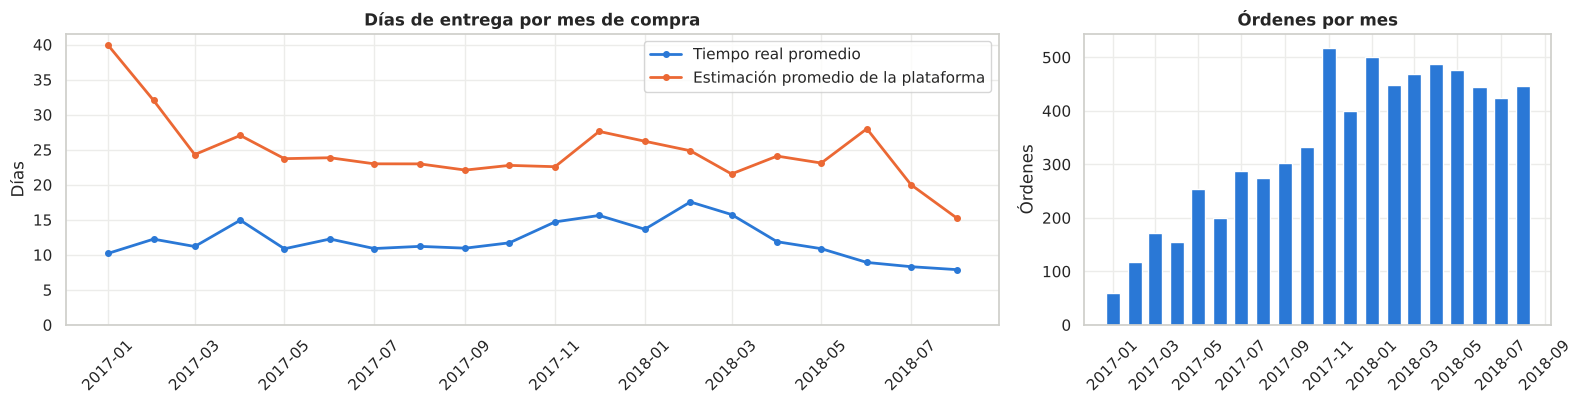

mes,2017-01,2017-02,2017-03,2017-04,2017-05,2017-06,2017-07,2017-08,2017-09,2017-10,2017-11,2017-12,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08
ordenes,59.0,118.0,171.0,154.0,254.0,200.0,288.0,274.0,302.0,333.0,518.0,399.0,501.0,449.0,469.0,488.0,477.0,445.0,423.0,447.0
real,10.2,12.2,11.2,14.9,10.9,12.3,10.9,11.2,10.9,11.7,14.7,15.6,13.6,17.5,15.7,11.9,10.9,8.9,8.3,7.9
estimado,39.9,32.0,24.3,27.0,23.7,23.9,23.0,23.0,22.1,22.8,22.6,27.6,26.2,24.8,21.5,24.1,23.1,28.0,20.0,15.3


In [13]:
mensual = (eda.assign(mes=eda[COL_FECHA_COMPRA].dt.to_period("M"))
           .groupby("mes").agg(ordenes=(TARGET, "size"), real=(TARGET, "mean"))
           .join(df.assign(mes=df[COL_FECHA_COMPRA].dt.to_period("M")).groupby("mes")["estimated_delivery_days"].mean().rename("estimado")))
mensual = mensual[mensual["ordenes"] >= 30]  # se omiten meses con muy pocas órdenes (2016)
x = mensual.index.to_timestamp()
fig, ax = plt.subplots(1, 2, figsize=(16, 4.2), gridspec_kw={"width_ratios": [2, 1]})
ax[0].plot(x, mensual["real"], color=AZUL, lw=2, marker="o", ms=4, label="Tiempo real promedio")
ax[0].plot(x, mensual["estimado"], color=NARANJO, lw=2, marker="o", ms=4, label="Estimación promedio de la plataforma")
ax[0].set(title="Días de entrega por mes de compra", ylabel="Días", ylim=(0, None)); ax[0].legend()
ax[1].bar(x, mensual["ordenes"], width=20, color=AZUL)
ax[1].set(title="Órdenes por mes", ylabel="Órdenes")
for a in ax: a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()
mensual.round(1).T

**Hallazgos:**
- Hay un **cambio fuerte en el tiempo (drift)**: el promedio sube a 14-17,5 días entre nov-2017 y mar-2018 (temporada alta de fin de año) y luego cae a ~8 días a mediados de 2018. La logística de la plataforma mejoró en el período.
- El volumen de órdenes crece en el tiempo; casi no hay datos de 2016.
- **Consecuencias:** (1) el mes de compra captura estacionalidad y es útil; (2) **no usamos el año** (`purchase_year`) como predictor, porque el modelo se usará con fechas futuras (2026 en la app) que quedan fuera del rango observado; (3) un modelo entrenado con el pasado podría sobreestimar en el futuro. En la sección 9.6 lo medimos con una **validación temporal complementaria**.

### 4.4 Geografía: ubicación del cliente y distancia al vendedor

Correlación distancia-target: 0.40


,count,mean,median
mismo_estado,,,
Distinto estado,4358,14.7,12.5
Mismo estado,2433,7.9,6.4


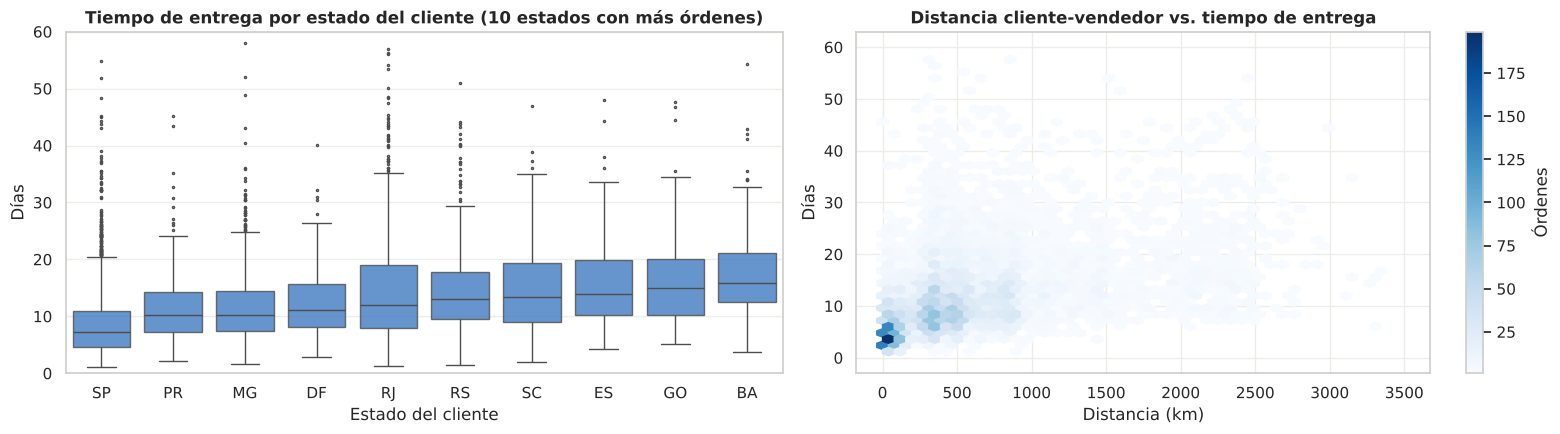

In [14]:
top_estados = df["customer_state"].value_counts().head(10).index
orden = df[df["customer_state"].isin(top_estados)].groupby("customer_state")[TARGET].median().sort_values().index
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
sns.boxplot(data=df[df["customer_state"].isin(top_estados)], x="customer_state", y=TARGET, order=orden, ax=ax[0],
            color=AZUL, fliersize=1.5, linewidth=1, boxprops=dict(alpha=0.8))
ax[0].set(ylim=(0, 60), title="Tiempo de entrega por estado del cliente (10 estados con más órdenes)", xlabel="Estado del cliente", ylabel="Días")
hb = ax[1].hexbin(eda["distancia_km"], eda[TARGET], gridsize=45, cmap="Blues", mincnt=1, extent=(0, 3500, 0, 60))
ax[1].set(title="Distancia cliente-vendedor vs. tiempo de entrega", xlabel="Distancia (km)", ylabel="Días")
fig.colorbar(hb, ax=ax[1], label="Órdenes")
plt.tight_layout(); plt.show()
print(f"Correlación distancia-target: {eda[['distancia_km', TARGET]].corr().iloc[0, 1]:.2f}")
display(eda.groupby("mismo_estado")[TARGET].agg(["count", "mean", "median"]).round(1)
        .rename(index={0: "Distinto estado", 1: "Mismo estado"}))

**Hallazgos:**
- La ubicación es clave: los clientes de **SP** (42% de las órdenes, donde están la mayoría de los vendedores) reciben en una mediana de ~7 días; los del norte y noreste (BA, PE, CE) tardan más del doble.
- La **distancia** cliente-vendedor tiene una correlación de 0,40 con el target, la mayor entre las variables legítimas. La relación es creciente pero con mucha dispersión.
- Comprar dentro del mismo estado reduce el tiempo de 14,7 a 7,9 días en promedio. Por eso creamos la variable `mismo_estado`.

### 4.5 Relaciones entre variables numéricas

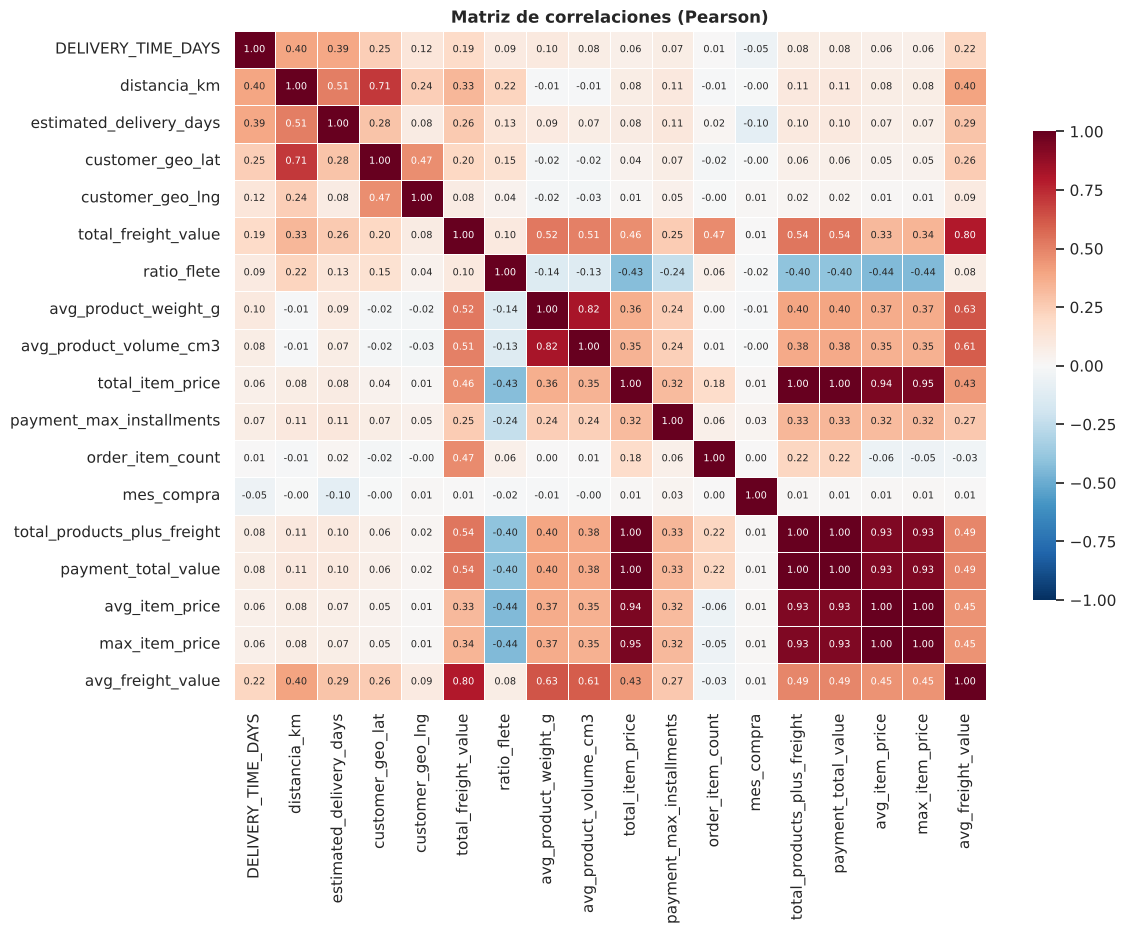

Correlación
total_products_plus_freight payment_total_value                1.000
avg_item_price              max_item_price                     0.999
total_item_price            total_products_plus_freight        0.996
                            payment_total_value                0.996
                            max_item_price                     0.947
                            avg_item_price                     0.944
total_products_plus_freight max_item_price                     0.934
payment_total_value         max_item_price                     0.934
total_products_plus_freight avg_item_price                     0.930
payment_total_value         avg_item_price                     0.930
avg_product_weight_g        avg_product_volume_cm3             0.822

In [15]:
cols_corr = [TARGET, "distancia_km", "estimated_delivery_days", "customer_geo_lat", "customer_geo_lng",
             "total_freight_value", "ratio_flete", "avg_product_weight_g", "avg_product_volume_cm3",
             "total_item_price", "payment_max_installments", "order_item_count", "mes_compra"]
extra_redundantes = df[["total_products_plus_freight", "payment_total_value", "avg_item_price", "max_item_price", "avg_freight_value"]]
matriz = pd.concat([eda[cols_corr], extra_redundantes], axis=1).corr()
fig, ax = plt.subplots(figsize=(12, 9.5))
sns.heatmap(matriz, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7},
            linewidths=0.5, linecolor="white", cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Matriz de correlaciones (Pearson)")
plt.tight_layout(); plt.show()

pares = matriz.where(np.triu(np.ones(matriz.shape, dtype=bool), k=1)).stack()
pares = pares[pares.abs() > 0.8].sort_values(ascending=False).round(3).to_frame("Correlación")
pares

**Hallazgos:**
- Ninguna variable numérica por sí sola explica mucho del target (la mayor correlación es 0,40), lo que anticipa un R² moderado. La relación es **no lineal** y depende de combinaciones (por ejemplo, distancia × estado), lo que favorece a modelos de árboles.
- Hay **variables casi idénticas** (|r| > 0,8): `payment_total_value` ≈ `total_products_plus_freight` ≈ `total_item_price` + flete, y `avg_item_price` ≈ `max_item_price` ≈ `total_item_price`. Usar todas no agrega información y genera multicolinealidad en el modelo lineal. **Conservamos una por concepto**: precio total (`total_item_price`) y flete total (`total_freight_value`).
- Las dimensiones del producto (largo, alto, ancho) quedan resumidas en el volumen.

### 4.6 Variables categóricas: medio de pago y categoría del producto

Categorías distintas: 67 | con menos de 20 órdenes: 35


,ordenes,dias_promedio,horas_aprobacion_mediana
payment_type_primary,,,
credit_card,5161,12.13,0.27
boleto,1313,12.87,27.84
voucher,210,11.70,0.29
debit_card,106,12.35,1.73


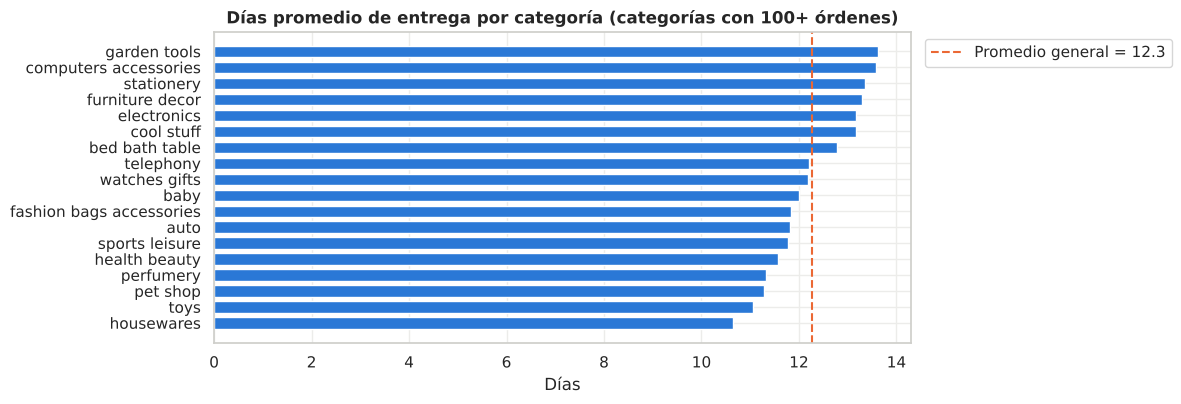

In [16]:
pago = df.groupby("payment_type_primary").agg(ordenes=(TARGET, "size"), dias_promedio=(TARGET, "mean"),
                                              horas_aprobacion_mediana=("approval_delay_hours", "median")).round(2)
display(pago.sort_values("ordenes", ascending=False))
cat = df.groupby("first_product_category_en")[TARGET].agg(["size", "mean"]).query("size >= 100").sort_values("mean")
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.barh(cat.index.str.replace("_", " "), cat["mean"], color=AZUL, height=0.7)
ax.axvline(y_all.mean(), color=NARANJO, ls="--", lw=1.5, label=f"Promedio general = {y_all.mean():.1f}")
ax.set(title="Días promedio de entrega por categoría (categorías con 100+ órdenes)", xlabel="Días")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0)); plt.tight_layout(); plt.show()
print("Categorías distintas:", df["first_product_category_en"].nunique(),
      "| con menos de 20 órdenes:", int((df["first_product_category_en"].value_counts() < 20).sum()))

**Hallazgos:**
- El **boleto** (pago en efectivo) tarda una mediana de 28 horas en aprobarse, frente a minutos con tarjeta. Esa demora se conoce recién **después** de comprar, pero el medio de pago sí se conoce al comprar: incluir `payment_type_primary` permite capturar ese efecto **sin fuga**.
- Las categorías con más órdenes tienen promedios distintos (de 10,6 a 13,6 días), lo que posiblemente refleja tamaño, peso y ubicación de los vendedores. Hay muchas categorías con pocas órdenes; en el preprocesamiento las agrupamos como "poco frecuentes" para no crear columnas con muy pocos datos.

### 4.7 Evidencia de fuga de información en los datos

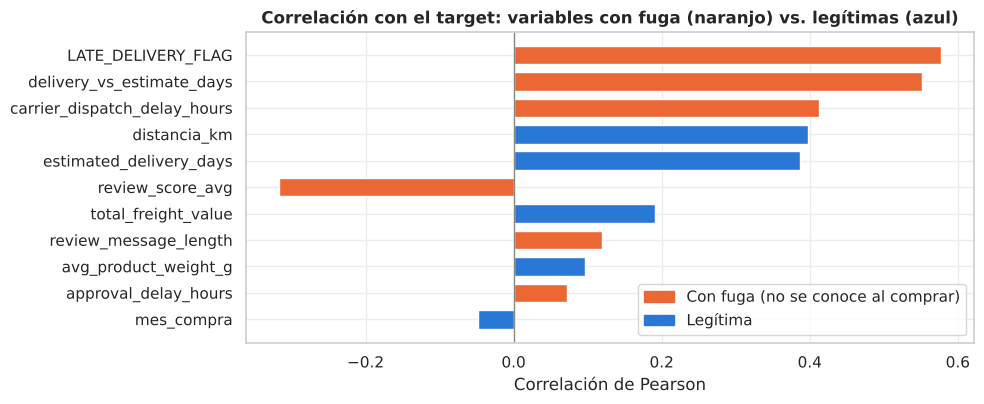

In [17]:
fuga = ["LATE_DELIVERY_FLAG", "delivery_vs_estimate_days", "carrier_dispatch_delay_hours", "review_score_avg",
        "review_message_length", "approval_delay_hours"]
legitimas = ["distancia_km", "estimated_delivery_days", "total_freight_value", "avg_product_weight_g", "mes_compra"]
corr_fuga = pd.concat([df[fuga], eda[legitimas]], axis=1).corrwith(y_all).sort_values(key=np.abs)
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.barh(corr_fuga.index, corr_fuga.values, color=[NARANJO if c in fuga else AZUL for c in corr_fuga.index], height=0.7)
ax.axvline(0, color=GRIS, lw=1)
ax.set(title="Correlación con el target: variables con fuga (naranjo) vs. legítimas (azul)", xlabel="Correlación de Pearson")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=NARANJO, label="Con fuga (no se conoce al comprar)"), Patch(color=AZUL, label="Legítima")], loc="lower right")
plt.tight_layout(); plt.show()

Las variables **más correlacionadas con el target son justamente las que no se pueden usar**: el flag de atraso y la diferencia con la estimación se calculan *con* la fecha de entrega; la demora del despacho ocurre durante el proceso; la nota de la reseña es baja *porque* el pedido llegó tarde (la causalidad va del target a la reseña, no al revés). Un modelo que las use se vería excelente en el notebook, pero sería **inutilizable** en la práctica, porque al momento de comprar esos datos no existen.

### 4.8 Resumen: del EDA a las decisiones

| Hallazgo del EDA | Decisión | Dónde se aplica |
|---|---|---|
| 1 fila = 1 orden, sin duplicados | No se agrupa; el split por filas mantiene la independencia Train/Test | §6 |
| 209 órdenes sin target (no entregadas) | Se excluyen | §3.1 |
| ~15 variables que solo se conocen después de la compra | Se excluyen (fuga); se cuantifica su efecto | §2.3, §7.2 |
| Target asimétrico con atípicos extremos (hasta 167 días) | Se comparan tres tratamientos: ninguno, log y recorte al percentil 99 en Train | §7.3 |
| Variables redundantes (\|r\| > 0,8) | Se conserva una por concepto | §5 |
| Ubicación y distancia relevantes, relación no lineal | Se crean `distancia_km` y `mismo_estado`; se prueban modelos de árboles | §5, §8 |
| Drift temporal; app usada con fechas futuras | Se excluye `purchase_year`; se hace una validación temporal complementaria | §5, §9.6 |
| La plataforma sobreestima por 12,7 días | Se usa como benchmark de negocio y como variable | §9 |
| Faltantes ≤ 1,4% | Imputación dentro del Pipeline (ajustada con Train) | §5 |
| Categorías con pocas órdenes | Se agrupan en "poco frecuentes" (< 20 órdenes en Train) | §5 |

## 5. Selección de variables y preprocesamiento

### 5.1 Variables finales
El modelo recibe **17 entradas** (todas conocidas al comprar), que se transforman en **22 variables**:

In [18]:
X_ejemplo = construir_variables(df[ENTRADAS].head(1))
tabla_vars = pd.DataFrame({
    "Variable": VARIABLES_NUMERICAS + VARIABLES_CATEGORICAS,
    "Tipo": ["Numérica"] * len(VARIABLES_NUMERICAS) + ["Categórica"] * len(VARIABLES_CATEGORICAS),
    "Origen": ["Dataset" if v in ENTRADAS else "Derivada (utils/features.py)" for v in VARIABLES_NUMERICAS + VARIABLES_CATEGORICAS],
})
print(f"Entradas: {len(ENTRADAS)} | Variables del modelo: {len(tabla_vars)}")
display(tabla_vars.style.hide(axis="index"))

Entradas: 17 | Variables del modelo: 22


Variable,Tipo,Origen
customer_geo_lat,Numérica,Dataset
customer_geo_lng,Numérica,Dataset
first_seller_geo_lat,Numérica,Dataset
first_seller_geo_lng,Numérica,Dataset
estimated_delivery_days,Numérica,Dataset
order_item_count,Numérica,Dataset
unique_seller_count,Numérica,Dataset
total_item_price,Numérica,Dataset
total_freight_value,Numérica,Dataset
avg_product_weight_g,Numérica,Dataset


**Variables derivadas** (se calculan en `utils/features.py` a partir de las entradas):
- `distancia_km`: distancia haversine (en línea recta sobre la Tierra) entre cliente y vendedor.
- `ratio_flete`: flete / (precio + flete).
- `mismo_estado`: 1 si cliente y vendedor están en el mismo estado.
- `mes_compra`, `dia_semana_compra`, `hora_compra`: se extraen de la fecha de compra.

El dataset ya traía versiones de algunas de estas variables. **Verificamos que nuestro cálculo es idéntico**; las recalculamos nosotros porque la app tiene que construirlas desde los datos que ingresa el usuario.

In [19]:
check = construir_variables(df[ENTRADAS])
print("distancia_km vs customer_first_seller_distance_km, dif. máx.:", round(np.nanmax(np.abs(check["distancia_km"] - df["customer_first_seller_distance_km"])), 4), "km")
print("ratio_flete vs freight_ratio, dif. máx.:                    ", round(np.nanmax(np.abs(check["ratio_flete"] - df["freight_ratio"])), 6))
print("mes/día/hora distintos a los del dataset:                   ",
      int((check["mes_compra"] != df["purchase_month"]).sum() + (check["dia_semana_compra"] != df["purchase_dayofweek"]).sum()
          + (check["hora_compra"] != df["purchase_hour"]).sum()))

distancia_km vs customer_first_seller_distance_km, dif. máx.: 0.0046 km
ratio_flete vs freight_ratio, dif. máx.:                     1e-06
mes/día/hora distintos a los del dataset:                    0


### 5.2 Pipeline de preprocesamiento

Todo lo que **aprende parámetros de los datos** va dentro de un `Pipeline` de scikit-learn. Así, cuando se ajusta el modelo con `fit(X_train, y_train)`, los parámetros (medianas, medias, desviaciones, categorías) se calculan **solo con Train**, y en Test o en la app solo se aplican.

| Paso | Variables | Qué hace | Por qué |
|---|---|---|---|
| `FunctionTransformer(construir_variables)` | Todas | Crea distancia, ratio de flete, mismo estado y mes/día/hora | Sin estado: no aprende nada de los datos |
| `SimpleImputer(median)` | Numéricas | Rellena faltantes con la mediana de Train | Robusta a atípicos (precio, peso y distancia son asimétricos) |
| `StandardScaler` | Numéricas | Centra y escala con media y desviación de Train | **Obligatorio en Elastic Net**: la penalización depende de la escala de los coeficientes. A los árboles no les afecta |
| `SimpleImputer(most_frequent)` | Categóricas | Rellena con la moda de Train | Solo 94 órdenes sin categoría |
| `OneHotEncoder(min_frequency=20, handle_unknown="infrequent_if_exist")` | Categóricas | Crea dummies; las categorías con menos de 20 órdenes en Train se agrupan en una dummy "poco frecuente" | Evita columnas casi vacías. Si en la app aparece una categoría nueva, cae en ese grupo en vez de provocar un error |

**Sobre las dummies c − 1 vs. c:** en clases se usan c − 1 dummies para evitar la colinealidad perfecta en la regresión lineal por MCO. Aquí mantenemos las c dummies porque (1) Elastic Net incluye una penalización que resuelve esa colinealidad, (2) a los árboles no les afecta y (3) con el grupo "poco frecuente" no existe una categoría de referencia natural.

In [20]:
def crear_preprocesador(num=VARIABLES_NUMERICAS, cat=VARIABLES_CATEGORICAS):
    numericas = Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler())])
    categoricas = Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                            ("dummies", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, sparse_output=False))])
    return ColumnTransformer([("num", numericas, num), ("cat", categoricas, cat)])


def crear_pipeline(modelo, num=VARIABLES_NUMERICAS, cat=VARIABLES_CATEGORICAS, con_variables=True):
    """Pipeline completo: [variables derivadas] -> imputación/escalamiento/dummies -> modelo."""
    pasos = [("variables", FunctionTransformer(construir_variables))] if con_variables else []
    pasos += [("preprocesamiento", crear_preprocesador(num, cat)), ("modelo", modelo)]
    return Pipeline(pasos)


crear_pipeline(GradientBoostingRegressor())

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('variables', ...), ('preprocesamiento', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function con...x7fac562f42c0>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=No

## 6. Train/Test Split

- **Proporción 80/20:** Train queda con 5.432 órdenes, suficientes para ajustar los modelos y para que cada fold de la validación cruzada entrene con unas 4.350. Test queda con 1.359 órdenes; con ese tamaño, el MAE de Test tiene un error estándar de solo ~0,17 días (se calcula abajo), así que la comparación final entre modelos es confiable.
- **Estratificado por deciles del target:** como la distribución tiene una cola larga, un split puramente aleatorio podría dejar más pedidos extremos en un conjunto que en otro. Estratificar asegura que Train y Test tengan la misma distribución de tiempos de entrega, incluidos los extremos.
- **Semilla fija** (`random_state=42`): la partición es reproducible.
- **El split se hace antes de cualquier preprocesamiento que estime parámetros.** Los pasos anteriores (filtrar órdenes entregadas, elegir columnas, calcular variables derivadas) no usan estadísticas de los datos, así que no filtran información de Test.
- Test **no se usa** para elegir variables, tratamientos ni hiperparámetros: todo eso se decide con validación cruzada dentro de Train. Test se usa **una sola vez**, en la sección 9.
- **¿Por qué no un split temporal?** Sería más realista para predecir el futuro, pero el período de Test quedaría con una distribución distinta (pedidos más rápidos, §4.3) y la comparación con la validación cruzada exigida por el enunciado se volvería difícil de interpretar. Usamos el split aleatorio estratificado como esquema principal y **evaluamos el escenario temporal por separado** en la sección 9.6.

In [21]:
X = df[ENTRADAS]
y = df[TARGET]
estratos = pd.qcut(y, q=10, labels=False)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEMILLA, stratify=estratos)

assert len(set(X_train.index) & set(X_test.index)) == 0
print(f"Train: {len(X_train):,} órdenes ({len(X_train)/len(X):.0%}) | Test: {len(X_test):,} órdenes ({len(X_test)/len(X):.0%})")
comparacion_split = pd.DataFrame({"Train": y_train.describe(percentiles=[.25, .5, .75, .95, .99]),
                                  "Test": y_test.describe(percentiles=[.25, .5, .75, .95, .99])}).round(2)
display(comparacion_split.T)
err_std = np.abs(y_test - y_train.median()).std() / np.sqrt(len(y_test))
print(f"Error estándar aproximado del MAE en Test: ±{err_std:.2f} días")

Train: 5,432 órdenes (80%) | Test: 1,359 órdenes (20%)
Error estándar aproximado del MAE en Test: ±0.17 días


,count,mean,std,min,25%,50%,75%,95%,99%,max
Train,5432.0,12.28,8.89,1.02,6.61,10.19,15.28,28.22,43.40,167.60
Test,1359.0,12.22,8.45,1.15,6.55,10.18,15.15,28.02,42.31,86.93


Train y Test tienen prácticamente la misma media, mediana y percentiles, incluido el percentil 99.

## 7. Decisiones previas validadas con datos

### 7.1 Herramienta de validación: K-Fold dentro de Train
Para tomar decisiones sin mirar Test usamos validación cruzada K-Fold (K = 5) **solo con Train**. La función `evaluar_cv` repite en cada fold:
1. Separa 4/5 de Train para ajustar y 1/5 para validar.
2. Aplica el tratamiento del target **solo a la parte de ajuste** (por ejemplo, recortar al percentil 99 calculado con esa parte).
3. Ajusta el Pipeline completo (variables, imputación, escalamiento, dummies y modelo) solo con la parte de ajuste.
4. Mide el error en la parte de validación **con los valores reales**, sin recortar.

Reporta el MAE de entrenamiento y de validación: si el de entrenamiento es mucho menor que el de validación, el modelo memoriza (**overfitting**); si ambos son altos y parecidos, el modelo es demasiado simple (**underfitting**).

**Métricas:**
- **MAE** (métrica principal): error absoluto promedio en días; es directa de interpretar para el negocio ("nos equivocamos en promedio X días").
- **RMSE**: castiga más los errores grandes; sirve para detectar si un modelo comete errores muy grandes.
- **R²**: proporción de la variabilidad explicada; sirve para comparar con un modelo que predice siempre el promedio (R² = 0).
- **Sesgo** = promedio de (predicción − real): negativo significa que el modelo **promete menos días de los que realmente toma** (el cliente recibe tarde).
- **% atraso > 5 días**: porcentaje de pedidos que llegan más de 5 días después de lo que predijo el modelo (el error más costoso para el negocio).

In [22]:
def metricas(y_real, y_pred):
    y_real, y_pred = np.asarray(y_real, dtype=float), np.asarray(y_pred, dtype=float)
    e = y_pred - y_real
    return {"MAE": np.mean(np.abs(e)), "RMSE": np.sqrt(np.mean(e ** 2)), "R2": r2_score(y_real, y_pred),
            "Sesgo": np.mean(e), "% atraso > 5 días": 100 * np.mean(e < -5)}


def preparar_target(X_fit, y_fit, tratamiento):
    """Tratamiento de atípicos del target, aplicado SOLO a los datos con que se ajusta el modelo."""
    if tratamiento == "recorte_p99":
        return X_fit, y_fit.clip(upper=y_fit.quantile(0.99))
    if tratamiento == "eliminar_iqr":
        q1, q3 = y_fit.quantile([.25, .75])
        mantener = y_fit <= q3 + 1.5 * (q3 - q1)
        return X_fit[mantener], y_fit[mantener]
    return X_fit, y_fit


def evaluar_cv(modelo, X, y, tratamiento="recorte_p99", k=5, devolver_predicciones=False):
    """K-Fold sobre los datos entregados (siempre Train). Devuelve métricas por fold."""
    kf = KFold(n_splits=k, shuffle=True, random_state=SEMILLA)

    def un_fold(i, idx_ajuste, idx_valid):
        m = clone(modelo)
        X_fit, y_fit = preparar_target(X.iloc[idx_ajuste], y.iloc[idx_ajuste], tratamiento)
        m.fit(X_fit, y_fit)
        pred_valid = m.predict(X.iloc[idx_valid])
        fila = {"Fold": i + 1, "MAE train": mean_absolute_error(y.iloc[idx_ajuste], m.predict(X.iloc[idx_ajuste]))}
        fila.update(metricas(y.iloc[idx_valid], pred_valid))
        return fila, pd.Series(pred_valid, index=y.index[idx_valid])

    salida = Parallel(n_jobs=-1)(delayed(un_fold)(i, a, b) for i, (a, b) in enumerate(kf.split(X)))
    folds = pd.DataFrame([s[0] for s in salida])
    if devolver_predicciones:
        return folds, pd.concat([s[1] for s in salida]).reindex(y.index)
    return folds


def resumen_cv(folds):
    r = folds.drop(columns="Fold").mean()
    r["Brecha (val − train)"] = r["MAE"] - r["MAE train"]
    return r.rename({"MAE": "MAE val"})


# Configuración de referencia para las decisiones previas (sus hiperparámetros se ajustan en la sección 8)
GB_REFERENCIA = GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8, random_state=SEMILLA)

### 7.2 ⚠️ Fuga de información (data leakage): qué pasaría si usáramos variables que no se conocen al comprar

Entrenamos el **mismo modelo** agregando grupos de variables con fuga. Si el error baja de forma espectacular, confirma que esas variables "conocen" el resultado y que el desempeño obtenido sería falso.

In [23]:
F_train = construir_variables(X_train)
escenarios_fuga = {
    "Sin fuga (variables disponibles al comprar)": [],
    "+ demoras del proceso (aprobación y despacho al transportista)": ["approval_delay_hours", "carrier_dispatch_delay_hours"],
    "+ reseña del cliente (nota promedio y mínima)": ["review_score_avg", "review_score_min"],
    "+ diferencia real vs. estimado (delivery_vs_estimate_days)": ["delivery_vs_estimate_days"],
}
filas = []
for nombre, cols in escenarios_fuga.items():
    F = pd.concat([F_train, df.loc[X_train.index, cols]], axis=1)
    pipe = crear_pipeline(GB_REFERENCIA, num=VARIABLES_NUMERICAS + cols, con_variables=False)
    filas.append({"Escenario": nombre, **resumen_cv(evaluar_cv(pipe, F, y_train))})
tabla_fuga = pd.DataFrame(filas).set_index("Escenario")[["MAE val", "RMSE", "R2"]]
tabla_fuga.round(3)

,MAE val,RMSE,R2
Escenario,,,
Sin fuga (variables disponibles al comprar),4.657,7.367,0.313
+ demoras del proceso (aprobación y despacho al transportista),4.035,6.708,0.431
+ reseña del cliente (nota promedio y mínima),4.367,6.906,0.397
+ diferencia real vs. estimado (delivery_vs_estimate_days),0.496,2.366,0.919


**Interpretación (dimensión crítica del proyecto):**
- Con `delivery_vs_estimate_days`, el MAE baja de 4,66 a **0,50 días** y el R² sube de 0,31 a **0,92**. Parece un modelo casi perfecto, pero esa variable es *días reales − días estimados*: contiene el target. En producción no existe, porque se calcula después de entregar.
- Las demoras del proceso (aprobación del pago y entrega al transportista) bajan el MAE a 4,04 y suben el R² a 0,43, pero ocurren después de la compra.
- La nota de la reseña también "mejora" el modelo (R² 0,40) porque los clientes ponen notas bajas cuando el pedido llega tarde: la reseña es **consecuencia** del atraso, no causa.
- **Decisión:** el modelo usa solo variables disponibles al momento de la compra. Aceptamos un desempeño menor (MAE ~4,7 días, R² ~0,31) a cambio de que sea **real y utilizable**. Un R² de 0,92 con fuga sería un resultado falso.
- **Nota:** si el negocio quisiera re-estimar la entrega más adelante (por ejemplo, cuando el vendedor despacha), las variables del proceso serían legítimas *en ese momento*, pero sería otro modelo para otra decisión de negocio.

### 7.3 Tratamiento de los atípicos del target

Comparamos cuatro alternativas con el mismo modelo y la misma validación cruzada. En todos los casos los folds de validación se evalúan con el **target real**, sin modificar:
- **Sin tratamiento.**
- **Eliminar atípicos (IQR):** sacar del ajuste las órdenes con target > Q3 + 1,5·IQR.
- **Transformación logarítmica:** el modelo aprende log(1 + días) y se vuelve a días con exp(x) − 1.
- **Recorte (winsorización) al percentil 99:** los targets sobre el percentil 99 del ajuste (~43 días) se reemplazan por ese valor; no se elimina ninguna orden.

In [24]:
pipe_ref = crear_pipeline(GB_REFERENCIA)
pipe_log = TransformedTargetRegressor(regressor=crear_pipeline(GB_REFERENCIA), func=np.log1p, inverse_func=np.expm1)
tratamientos = {
    "Sin tratamiento": (pipe_ref, "ninguno"),
    "Eliminar atípicos (IQR)": (pipe_ref, "eliminar_iqr"),
    "Transformación logarítmica": (pipe_log, "ninguno"),
    "Recorte al percentil 99": (pipe_ref, "recorte_p99"),
}
tabla_target = pd.DataFrame({n: resumen_cv(evaluar_cv(m, X_train, y_train, tratamiento=t)) for n, (m, t) in tratamientos.items()}).T
tabla_target[["MAE val", "RMSE", "R2", "Sesgo", "% atraso > 5 días"]].round(3)

,MAE val,RMSE,R2,Sesgo,% atraso > 5 días
Sin tratamiento,4.733,7.485,0.291,0.075,15.280
Eliminar atípicos (IQR),4.551,7.540,0.281,-1.112,18.299
Transformación logarítmica,4.443,7.452,0.297,-1.228,18.170
Recorte al percentil 99,4.657,7.367,0.313,-0.080,15.206


**Interpretación y decisión:**
- **Eliminar atípicos** baja el MAE (4,73 → 4,55), pero sesga el modelo hacia abajo (sesgo −1,1 días) y sube los pedidos que llegan más de 5 días tarde (15,3% → 18,3%). El modelo "olvida" que existen pedidos lentos, que en la realidad siguen ocurriendo.
- **Logaritmo:** tiene el MAE más bajo (4,44), porque al volver a días predice algo cercano a la *mediana* en vez del promedio. El costo es un **sesgo negativo** (−1,2 días) y más pedidos con atraso > 5 días (18,2%). Para el negocio, prometer de menos es el error más caro.
- **Recorte al percentil 99:** frente a no hacer nada, tiene el **mejor RMSE (7,37) y R² (0,313)**, un MAE algo menor (4,66) y **mantiene el sesgo cerca de cero** (−0,08) y los atrasos en 15,2%. Reduce la influencia de ~1% de casos extremos (hasta 167 días) en la pérdida cuadrática sin eliminar órdenes y sin distorsionar las predicciones.
- **Decisión: recorte al percentil 99, aplicado solo al target de entrenamiento.** El percentil se calcula con los datos de ajuste (en cada fold o en Train completo), y Test siempre se evalúa con los valores reales. No elegimos el menor MAE a ciegas: elegimos el tratamiento con el mejor equilibrio entre error, sesgo y costo de negocio.

### 7.4 Variables candidatas adicionales
Probamos agregar, una a la vez, variables que descartamos en la sección 2.3, para confirmar con datos que no aportan o para dejar explícito por qué se excluyen aunque aporten.

In [25]:
df["dias_limite_despacho"] = (df["shipping_limit_date_max"] - df["order_purchase_timestamp"]).dt.total_seconds() / 86400
candidatas = ["avg_product_photos_qty", "avg_product_description_length", "customer_geo_points",
              "unique_product_categories", "purchase_year", "dias_limite_despacho"]
filas = [{"Variable agregada": "(ninguna: modelo base)", **resumen_cv(evaluar_cv(crear_pipeline(GB_REFERENCIA, con_variables=False), F_train, y_train))}]
for c in candidatas:
    F = pd.concat([F_train, df.loc[X_train.index, [c]]], axis=1)
    pipe = crear_pipeline(GB_REFERENCIA, num=VARIABLES_NUMERICAS + [c], con_variables=False)
    filas.append({"Variable agregada": c, **resumen_cv(evaluar_cv(pipe, F, y_train))})
tabla_candidatas = pd.DataFrame(filas).set_index("Variable agregada")[["MAE val", "RMSE", "R2"]]
tabla_candidatas["Cambio en MAE"] = tabla_candidatas["MAE val"] - tabla_candidatas.iloc[0]["MAE val"]
tabla_candidatas.round(3)

,MAE val,RMSE,R2,Cambio en MAE
Variable agregada,,,,
(ninguna: modelo base),4.657,7.367,0.313,0.000
avg_product_photos_qty,4.661,7.362,0.314,0.003
avg_product_description_length,4.664,7.364,0.314,0.007
customer_geo_points,4.664,7.372,0.312,0.007
unique_product_categories,4.666,7.381,0.311,0.008
purchase_year,4.578,7.275,0.330,-0.080
dias_limite_despacho,4.590,7.294,0.327,-0.067


**Decisión:**
- Fotos, largo de la descripción, densidad de puntos geográficos y n° de categorías **no mejoran** el MAE (cambios dentro del ruido de la validación cruzada, ~±0,05 días): se excluyen, y así la app pide menos datos.
- `purchase_year` y `dias_limite_despacho` **sí mejoran** el MAE (en 0,08 y 0,07 días), pero **se excluyen igual**:
  - El año solo distingue 2017 de 2018. La app se usará con fechas de 2026, fuera del rango observado, así que el modelo tendría que extrapolar un efecto que no se puede proyectar.
  - La fecha límite de despacho se fija **cuando se aprueba el pago** (es la fecha de aprobación más un plazo), no al comprar.
- Preferimos un modelo un poco menos preciso en el papel pero **válido en el momento en que se usa**. Es el mismo criterio de la sección 7.2.

## 8. Modelos candidatos e hiperparámetros

Evaluamos tres familias de modelos vistas en clases, con niveles de flexibilidad distintos:

| Modelo | Familia | Por qué es candidato |
|---|---|---|
| **Elastic Net** | Regresión lineal regularizada (Ridge + Lasso) | Interpretable; sirve de referencia lineal. Su hiperparámetro `l1_ratio` cubre Ridge (0) y Lasso (1) |
| **Random Forest** | Ensamble *bagging* de árboles | Captura no linealidades e interacciones (distancia × estado); promediar árboles reduce la varianza |
| **Gradient Boosting** | Ensamble *boosting* de árboles | Cada árbol corrige los errores del anterior; suele ser el más preciso en datos tabulares |

Antes de los modelos calculamos los **baselines**: un modelo que no aprende nada (predice siempre el promedio o la mediana de Train) y la estimación actual de la plataforma. Un modelo útil tiene que superarlos claramente.

Todos los hiperparámetros se eligen con la validación cruzada de 5 folds dentro de Train (§7.1). Test no se toca.

In [26]:
filas = {}
for nombre, estrategia in [("Baseline: promedio de Train", "mean"), ("Baseline: mediana de Train", "median")]:
    filas[nombre] = resumen_cv(evaluar_cv(DummyRegressor(strategy=estrategia), X_train, y_train, tratamiento="ninguno"))
filas["Estimación de la plataforma"] = pd.Series(metricas(y_train, X_train["estimated_delivery_days"])).rename({"MAE": "MAE val"})
tabla_baselines = pd.DataFrame(filas).T[["MAE val", "RMSE", "R2", "Sesgo", "% atraso > 5 días"]]
tabla_baselines.round(3)

,MAE val,RMSE,R2,Sesgo,% atraso > 5 días
Baseline: promedio de Train,6.156,8.884,-0.000,-0.000,19.533
Baseline: mediana de Train,5.921,9.130,-0.057,-2.097,25.405
Estimación de la plataforma,12.804,15.156,-1.904,11.510,3.921


Predecir siempre el promedio da un MAE de 6,16 días. La estimación de la plataforma tiene un R² de −1,9: como sobreestima en 11,5 días, es **peor que predecir el promedio** (aunque casi nunca llega tarde). Estos son los números a superar.

In [27]:
def grafico_curva(ax, x, tabla, titulo, xlabel, log=False, marcar=None):
    ax.plot(x, tabla["MAE train"], color=AZUL, lw=2, marker="o", ms=5, label="MAE entrenamiento")
    ax.plot(x, tabla["MAE val"], color=NARANJO, lw=2, marker="o", ms=5, label="MAE validación (CV)")
    if marcar is not None:
        ax.axvline(marcar, color=GRIS, ls="--", lw=1.2, label="Valor elegido")
    if log:
        ax.set_xscale("log")
    ax.set(title=titulo, xlabel=xlabel, ylabel="MAE (días)")
    ax.legend(fontsize=9)


def barrido(crear_modelo, valores, tratamiento="recorte_p99"):
    """Evalúa con CV un modelo para cada valor de un hiperparámetro."""
    filas = []
    for v in valores:
        t = time.time()
        r = resumen_cv(evaluar_cv(crear_pipeline(crear_modelo(v)), X_train, y_train, tratamiento=tratamiento))
        r["Segundos"] = time.time() - t
        filas.append(r)
    return pd.DataFrame(filas, index=pd.Index(valores, name="valor"))

### 8.1 Elastic Net

Minimiza el error cuadrático más una penalización sobre los coeficientes: `alpha · [l1_ratio·Σ|β| + (1 − l1_ratio)/2·Σβ²]`.
- `alpha` (λ en clases): fuerza de la penalización. Con valores altos, los coeficientes se van a cero y el modelo subajusta.
- `l1_ratio`: mezcla entre Lasso (1: puede dejar coeficientes en cero exacto y seleccionar variables) y Ridge (0: encoge todos los coeficientes sin anularlos).

Mejor combinación: ('l1_ratio=1.0', np.float64(0.01)) → MAE val = 4.983


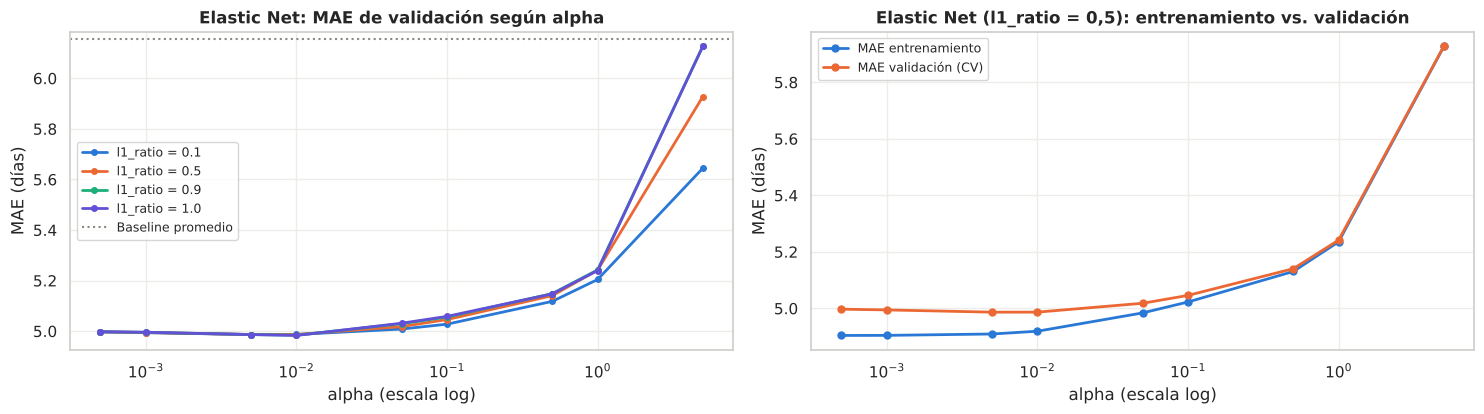

,l1_ratio=0.1,l1_ratio=0.5,l1_ratio=0.9,l1_ratio=1.0
valor,,,,
0.0005,4.997,4.997,4.998,4.998
0.0010,4.994,4.995,4.995,4.996
0.0050,4.987,4.987,4.987,4.987
0.0100,4.987,4.987,4.984,4.983
0.0500,5.008,5.018,5.030,5.031
0.1000,5.028,5.046,5.056,5.059
0.5000,5.118,5.140,5.149,5.148
1.0000,5.204,5.242,5.242,5.240
5.0000,5.645,5.928,6.127,6.127


In [28]:
alphas = [0.0005, 0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1.0, 5.0]
l1_ratios = [0.1, 0.5, 0.9, 1.0]
resultados_en = {}
for l1 in l1_ratios:
    resultados_en[l1] = barrido(lambda a: ElasticNet(alpha=a, l1_ratio=l1, max_iter=20000), alphas)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.3))
colores = [AZUL, NARANJO, VERDE, "#6250d6"]
for (l1, tabla), col in zip(resultados_en.items(), colores):
    ax[0].plot(alphas, tabla["MAE val"], marker="o", ms=4, lw=2, color=col, label=f"l1_ratio = {l1}")
ax[0].axhline(tabla_baselines.loc["Baseline: promedio de Train", "MAE val"], color=GRIS, ls=":", label="Baseline promedio")
ax[0].set(xscale="log", title="Elastic Net: MAE de validación según alpha", xlabel="alpha (escala log)", ylabel="MAE (días)")
ax[0].legend(fontsize=9)
grafico_curva(ax[1], alphas, resultados_en[0.5], "Elastic Net (l1_ratio = 0,5): entrenamiento vs. validación", "alpha (escala log)", log=True)
plt.tight_layout(); plt.show()

tabla_en = pd.concat({f"l1_ratio={k}": v[["MAE train", "MAE val", "Brecha (val − train)", "R2"]] for k, v in resultados_en.items()})
mejor_en = tabla_en["MAE val"].idxmin()
print("Mejor combinación:", mejor_en, "→ MAE val =", round(tabla_en.loc[mejor_en, "MAE val"], 3))
tabla_en.unstack(0)["MAE val"].round(3)

**Interpretación:**
- **Underfitting con alpha alto:** al aumentar alpha el error sube. Con alpha = 5 y `l1_ratio` ≥ 0,9, el MAE llega a 6,13, igual al baseline (6,16): la penalización anula casi todos los coeficientes y el modelo es demasiado simple.
- **Con alpha bajo no aparece overfitting:** el MAE de entrenamiento y el de validación son casi iguales (brecha < 0,1 días). Con ~85 columnas y 4.300 filas, un modelo lineal no tiene capacidad para memorizar.
- El mejor MAE de validación (4,98 días) **sigue siendo alto incluso con muy poca penalización**, y la brecha es mínima. Eso indica que el problema del modelo lineal es el **sesgo**, no la varianza: la relación entre las variables y el tiempo de entrega no es lineal (por ejemplo, el efecto de la distancia depende del estado). Por eso necesitamos modelos más flexibles.
- `l1_ratio` casi no cambia el resultado con alpha bajo (todas las combinaciones con alpha ≤ 0,01 están entre 4,98 y 5,00). Con alpha alto, más Lasso (`l1_ratio` cercano a 1) anula coeficientes antes y subajusta más.
- **Elegido: `alpha` = 0,01 y `l1_ratio` = 1 (Lasso)**, el menor MAE de validación. Además, Lasso deja 54 de los 85 coeficientes distintos de cero: hace una selección automática de variables y elimina dummies poco útiles.

Elastic Net elegido: alpha = 0.01, l1_ratio = 1.0
Coeficientes distintos de cero: 54 de 85


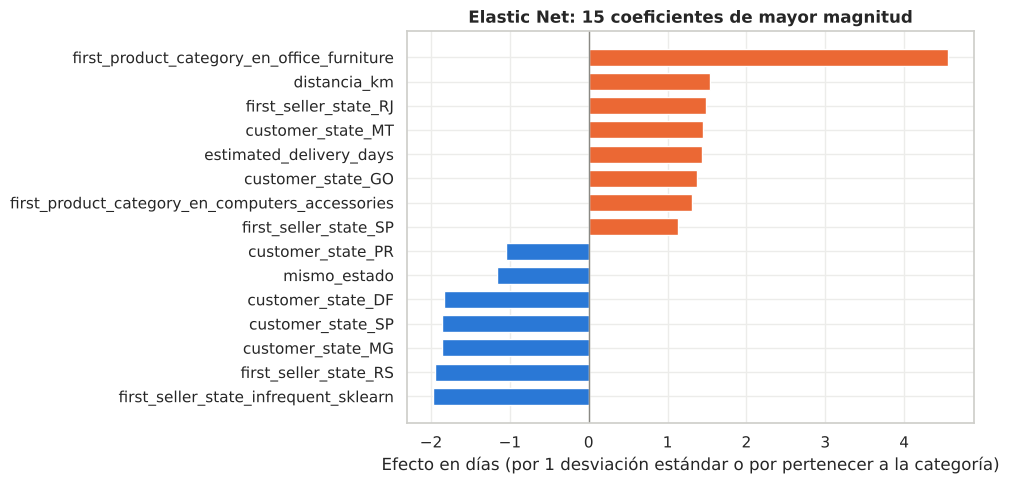

In [29]:
l1_en, alpha_en = float(mejor_en[0].split("=")[1]), float(mejor_en[1])
modelo_en = crear_pipeline(ElasticNet(alpha=alpha_en, l1_ratio=l1_en, max_iter=20000))
print(f"Elastic Net elegido: alpha = {alpha_en}, l1_ratio = {l1_en}")

# Coeficientes (variables escaladas): qué variables aumentan o reducen el tiempo de entrega
_m = clone(modelo_en).fit(*preparar_target(X_train, y_train, "recorte_p99"))
nombres = _m.named_steps["preprocesamiento"].get_feature_names_out()
coefs = pd.Series(_m.named_steps["modelo"].coef_, index=[n.split("__", 1)[1] for n in nombres])
print(f"Coeficientes distintos de cero: {(coefs != 0).sum()} de {len(coefs)}")
top = coefs[coefs.abs().sort_values(ascending=False).index[:15]].sort_values()
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top.index, top.values, color=[NARANJO if v > 0 else AZUL for v in top.values], height=0.7)
ax.axvline(0, color=GRIS, lw=1)
ax.set(title="Elastic Net: 15 coeficientes de mayor magnitud", xlabel="Efecto en días (por 1 desviación estándar o por pertenecer a la categoría)")
plt.tight_layout(); plt.show()

Los coeficientes son coherentes con el EDA:
- **Aumentan el tiempo:** más distancia y un plazo mayor informado por la plataforma. Los muebles de oficina (productos voluminosos) tardan ~4,5 días más.
- **Lo reducen:** ser cliente de SP, MG, DF o PR, o comprar en el mismo estado.
- Esta interpretabilidad es la principal ventaja del modelo lineal.
- El **mes de compra no aparece** entre los coeficientes importantes, aunque en el EDA era clave. Su efecto no es lineal (sube entre noviembre y marzo y baja después), y una recta no puede representarlo: es otro ejemplo del sesgo del modelo lineal que motiva usar árboles.

### 8.2 Random Forest

Promedia muchos árboles, cada uno entrenado con una muestra *bootstrap* de los datos y considerando en cada división solo una fracción aleatoria de las variables. Hiperparámetros explorados:
- `max_depth`: profundidad máxima de cada árbol (complejidad).
- `min_samples_leaf`: mínimo de órdenes en cada hoja; valores altos suavizan las predicciones.
- `max_features`: fracción de variables candidatas en cada división; valores bajos decorrelacionan los árboles.
- `n_estimators`: número de árboles. Más árboles reducen la varianza del promedio, pero no causan overfitting; solo cuestan tiempo.

Exploramos un hiperparámetro a la vez, dejando los demás fijos, para aislar su efecto.

In [30]:
def rf(**kw):
    # n_jobs=1: el paralelismo se hace entre folds (evaluar_cv), no dentro de cada bosque
    base = dict(n_estimators=100, max_features=0.5, min_samples_leaf=1, max_depth=None, random_state=SEMILLA, n_jobs=1)
    base.update(kw)
    return RandomForestRegressor(**base)

t0 = time.time()
rf_depth = barrido(lambda v: rf(max_depth=v), [2, 4, 6, 8, 10, 14, None])
rf_leaf = barrido(lambda v: rf(min_samples_leaf=v), [1, 2, 5, 10, 20, 50, 100])
rf_feat = barrido(lambda v: rf(min_samples_leaf=5, max_features=v), [0.1, 0.2, 0.33, 0.5, 0.75, 1.0])
rf_trees = barrido(lambda v: rf(min_samples_leaf=5, n_estimators=v), [10, 25, 50, 100, 200, 400])
rf_depth.index = ["None" if pd.isna(v) else str(int(v)) for v in rf_depth.index]
print(f"Barridos de Random Forest: {time.time() - t0:.0f} s")

Barridos de Random Forest: 142 s


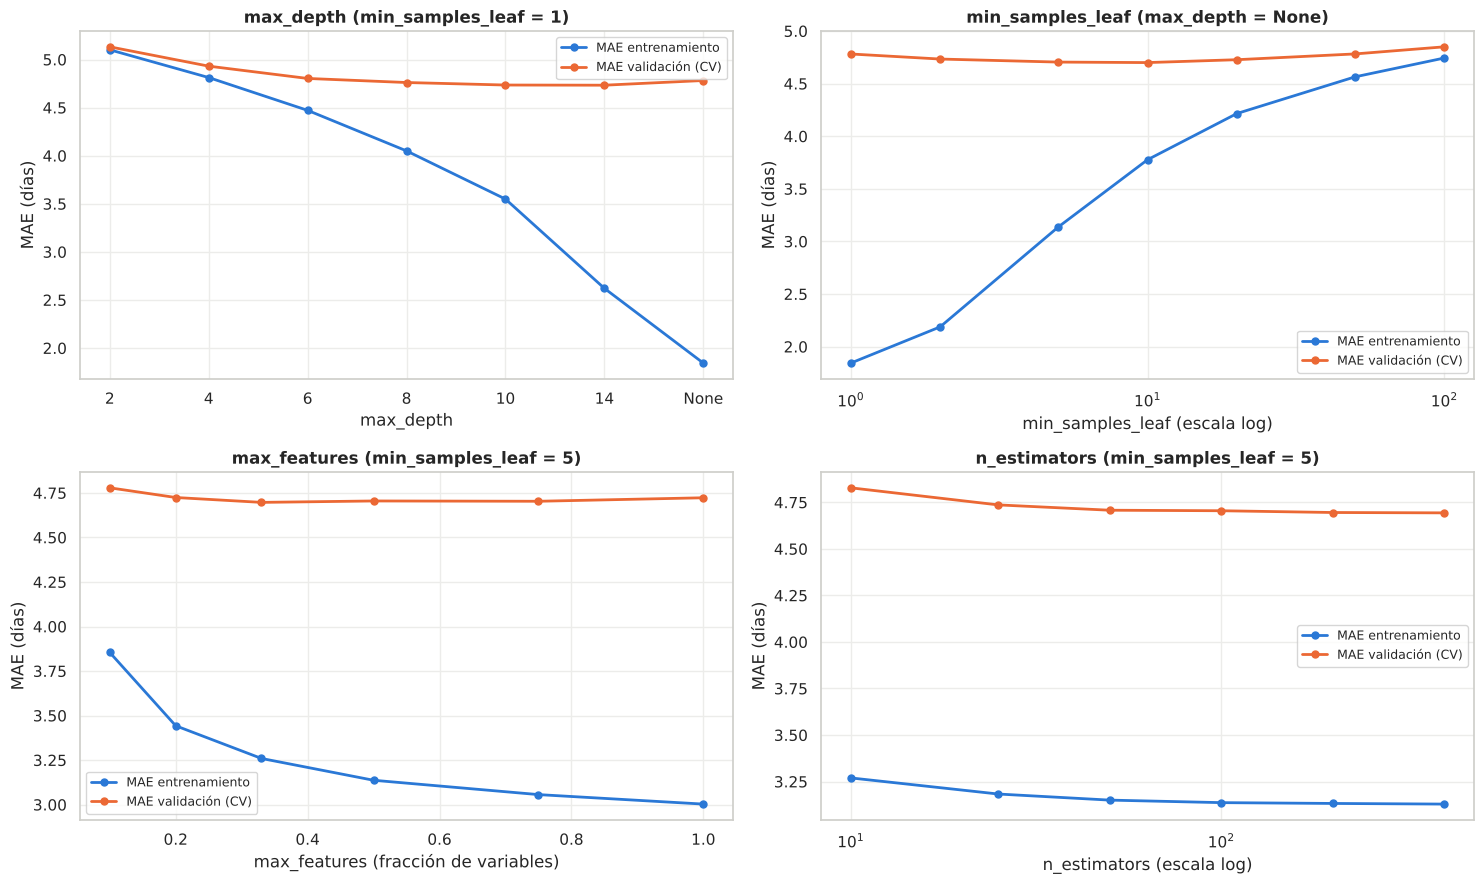

MAE train  MAE val  Brecha (val − train)     R2  Segundos
max_depth        2         5.101    5.132                 0.031  0.210     1.553
                 4         4.813    4.931                 0.119  0.254     2.465
                 6         4.471    4.803                 0.332  0.282     3.188
                 8         4.050    4.761                 0.711  0.294     4.301
                 10        3.549    4.735                 1.186  0.299     4.800
                 14        2.621    4.733                 2.112  0.303     6.540
                 None      1.844    4.782                 2.938  0.298     8.395
min_samples_leaf 1         1.844    4.782                 2.938  0.298     8.691
                 2         2.188    4.734                 2.546  0.302     7.274
                 5         3.137    4.705                 1.568  0.309     5.439
                 10        3.777    4.700                 0.923  0.308     4.806
                 20        4.216    4.727                 0.512  0.301     4.470
                 50        4.564    4.782                 0.218  0.287     3.786
                 100       4.743    4.850                 0.106  0.271     2.812
max_features     0.1       3.854    4.779                 0.924  0.291     1.947
                 0.2       3.443    4.724                 1.281  0.302     2.832
                 0.33      3.259    4.697                 1.438  0.308     4.068
                 0.5       3.137    4.705                 1.568  0.309     5.656
                 0.75      3.056    4.703                 1.647  0.308     7.449
                 1         3.003    4.723                 1.720  0.302     9.434
n_estimators     10        3.270    4.828                 1.558  0.278     0.803
                 25        3.183    4.736                 1.553  0.298     1.629
                 50        3.150    4.708                 1.557  0.306     2.729
                 100       3.137    4.705                 1.568  0.309     5.254
                 200       3.133    4.695                 1.563  0.310    10.322
                 400       3.129    4.693                 1.564  0.311    21.053

In [31]:
fig, ax = plt.subplots(2, 2, figsize=(15, 9))
grafico_curva(ax[0, 0], list(rf_depth.index), rf_depth, "max_depth (min_samples_leaf = 1)", "max_depth")
grafico_curva(ax[0, 1], rf_leaf.index, rf_leaf, "min_samples_leaf (max_depth = None)", "min_samples_leaf (escala log)", log=True)
grafico_curva(ax[1, 0], rf_feat.index, rf_feat, "max_features (min_samples_leaf = 5)", "max_features (fracción de variables)")
grafico_curva(ax[1, 1], rf_trees.index, rf_trees, "n_estimators (min_samples_leaf = 5)", "n_estimators (escala log)", log=True)
plt.tight_layout(); plt.show()
pd.concat({"max_depth": rf_depth, "min_samples_leaf": rf_leaf, "max_features": rf_feat, "n_estimators": rf_trees})[
    ["MAE train", "MAE val", "Brecha (val − train)", "R2", "Segundos"]].round(3)

**Interpretación:**
- **`max_depth`:** con profundidad 2 el modelo **subajusta** (MAE de 5,10 en entrenamiento y 5,13 en validación: ambos altos y parecidos). Al aumentar la profundidad, el error de entrenamiento cae hasta 1,84 sin límite, mientras el de validación se queda en ~4,73-4,78. Los árboles sin límite y con hojas de 1 orden **memorizan** Train (overfitting, brecha de 2,9 días). Aun así, el MAE de validación no empeora mucho, porque el promedio de muchos árboles compensa parte de la varianza (para eso sirve el bagging).
- **`min_samples_leaf`:** es la forma más efectiva de controlar el overfitting. Al pasar de 1 a 5-10 órdenes por hoja, la brecha baja de 2,9 a 0,9-1,6 días y el MAE de validación mejora (4,78 → 4,70). Con 50-100 el modelo empieza a subajustar (validación 4,78-4,85).
- **`max_features`:** con 10% de las variables cada división tiene poca información (validación 4,78); con 100%, los árboles se parecen demasiado entre sí y el promedio pierde su efecto (4,72). El óptimo está en una zona intermedia (0,33: 4,70).
- **`n_estimators`:** el error baja de 4,83 (10 árboles) a 4,71 (100) y luego casi no cambia (4,69 con 400). Más árboles no empeoran el modelo (no producen overfitting), solo aumentan el tiempo y el tamaño del archivo.

Con estos rangos hacemos una **grilla final** combinando `min_samples_leaf` y `max_features`, con 300 árboles.

In [32]:
grilla_rf = [(leaf, mf) for leaf in [3, 5, 10] for mf in [0.33, 0.5]]
t0 = time.time()
res_grilla_rf = pd.DataFrame([resumen_cv(evaluar_cv(crear_pipeline(rf(n_estimators=300, min_samples_leaf=l, max_features=m)), X_train, y_train))
                              for l, m in grilla_rf], index=pd.MultiIndex.from_tuples(grilla_rf, names=["min_samples_leaf", "max_features"]))
print(f"Grilla final RF: {time.time() - t0:.0f} s")
res_grilla_rf[["MAE train", "MAE val", "Brecha (val − train)", "RMSE", "R2", "Sesgo"]].round(3)

Grilla final RF: 82 s


MAE train  MAE val  Brecha (val − train)   RMSE     R2  Sesgo
min_samples_leaf max_features                                                               
3                0.33              2.686    4.697                 2.011  7.381  0.311 -0.021
                 0.50              2.572    4.695                 2.123  7.375  0.312 -0.005
5                0.33              3.249    4.694                 1.445  7.389  0.309 -0.062
                 0.50              3.130    4.696                 1.565  7.381  0.311 -0.048
10               0.33              3.862    4.708                 0.847  7.405  0.306 -0.098
                 0.50              3.771    4.698                 0.927  7.389  0.309 -0.091

In [33]:
leaf_rf, mf_rf = res_grilla_rf["MAE val"].idxmin()
params_rf = dict(n_estimators=300, max_depth=None, min_samples_leaf=int(leaf_rf), max_features=float(mf_rf))
modelo_rf = crear_pipeline(RandomForestRegressor(**params_rf, random_state=SEMILLA, n_jobs=1))
print("Random Forest elegido:", params_rf)

Random Forest elegido: {'n_estimators': 300, 'max_depth': None, 'min_samples_leaf': 5, 'max_features': 0.33}


**Elegido: `min_samples_leaf` = 5, `max_features` = 0,33, 300 árboles, sin límite de profundidad.**
- En la grilla, las seis combinaciones quedan entre 4,694 y 4,708. Las diferencias son menores que la variabilidad entre folds (~0,04 días), así que cualquiera es razonable. Elegimos la de menor MAE de validación, que además tiene una brecha menor que la de `min_samples_leaf` = 3 (1,4 vs. 2,0 días).
- No limitamos la profundidad, porque el control de complejidad lo hace `min_samples_leaf`, que fue más efectivo en los barridos.
- Usamos 300 árboles porque sobre ~100 la mejora es marginal y 300 da predicciones estables.

### 8.3 Gradient Boosting

Construye árboles pequeños **en secuencia**: cada árbol nuevo modela los errores (residuos) que dejaron los anteriores, y su aporte se multiplica por la tasa de aprendizaje. Hiperparámetros explorados:
- `learning_rate` y `n_estimators`: están ligados. Una tasa baja necesita más árboles pero generaliza mejor; una tasa alta aprende rápido pero se sobreajusta pronto.
- `max_depth`: complejidad de cada árbol (cuántas interacciones entre variables puede capturar).
- `min_samples_leaf` y `subsample` (fracción de datos que usa cada árbol): regularización adicional.

**Curvas de aprendizaje:** `staged_predict` entrega la predicción después de cada árbol, así que con un solo ajuste por fold obtenemos el error para 1, 2, …, 800 árboles.

Curvas de learning_rate: 175 s


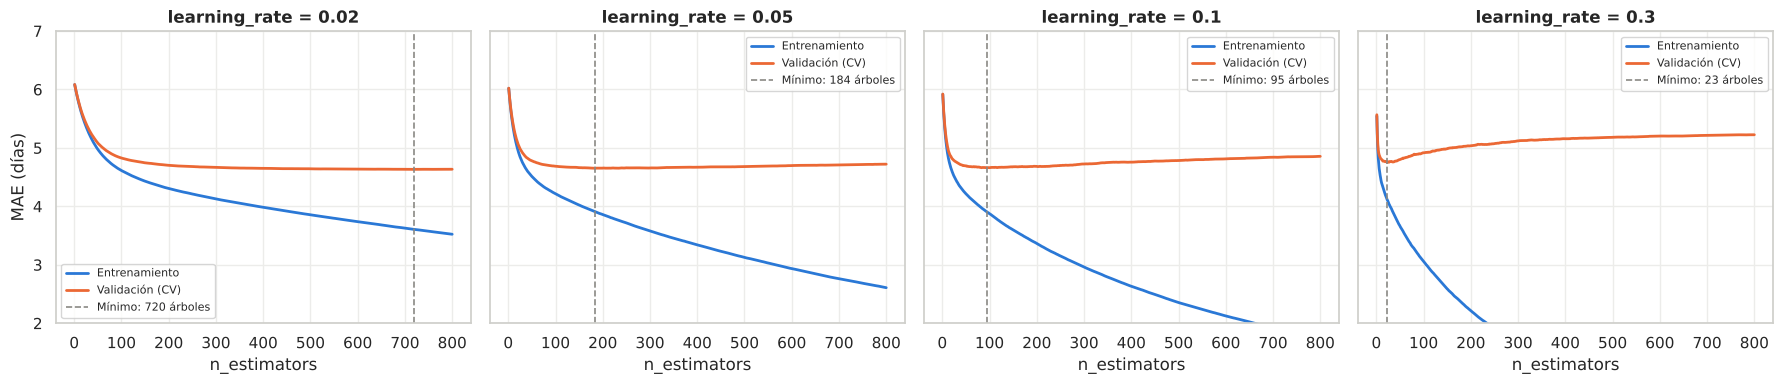

,n_estimators óptimo,MAE val mínimo,MAE train en el óptimo,MAE val con 800 árboles
0.02,720.0,4.633,3.606,4.635
0.05,184.0,4.652,3.909,4.722
0.10,95.0,4.662,3.902,4.856
0.30,23.0,4.753,4.113,5.225


In [34]:
def curva_gb(params, max_arboles=800, k=5):
    kf = KFold(n_splits=k, shuffle=True, random_state=SEMILLA)

    def un_fold(idx_ajuste, idx_valid):
        X_fit, y_fit = preparar_target(X_train.iloc[idx_ajuste], y_train.iloc[idx_ajuste], "recorte_p99")
        pipe = crear_pipeline(GradientBoostingRegressor(n_estimators=max_arboles, random_state=SEMILLA, **params)).fit(X_fit, y_fit)
        Z_aj, Z_va = pipe[:-1].transform(X_train.iloc[idx_ajuste]), pipe[:-1].transform(X_train.iloc[idx_valid])
        gb = pipe[-1]
        tr = [mean_absolute_error(y_train.iloc[idx_ajuste], p) for p in gb.staged_predict(Z_aj)]
        va = [mean_absolute_error(y_train.iloc[idx_valid], p) for p in gb.staged_predict(Z_va)]
        return np.array(tr), np.array(va)

    res = Parallel(n_jobs=-1)(delayed(un_fold)(a, b) for a, b in kf.split(X_train))
    return pd.DataFrame({"MAE train": np.mean([r[0] for r in res], axis=0),
                         "MAE val": np.mean([r[1] for r in res], axis=0)}, index=pd.RangeIndex(1, max_arboles + 1, name="n_estimators"))

t0 = time.time()
curvas_lr = {lr: curva_gb(dict(learning_rate=lr, max_depth=4, subsample=0.8)) for lr in [0.02, 0.05, 0.1, 0.3]}
print(f"Curvas de learning_rate: {time.time() - t0:.0f} s")

fig, ax = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for a, (lr, c) in zip(ax, curvas_lr.items()):
    a.plot(c.index, c["MAE train"], color=AZUL, lw=2, label="Entrenamiento")
    a.plot(c.index, c["MAE val"], color=NARANJO, lw=2, label="Validación (CV)")
    n_opt = c["MAE val"].idxmin()
    a.axvline(n_opt, color=GRIS, ls="--", lw=1.2, label=f"Mínimo: {n_opt} árboles")
    a.set(title=f"learning_rate = {lr}", xlabel="n_estimators", ylim=(2, 7))
    a.legend(fontsize=8)
ax[0].set_ylabel("MAE (días)")
plt.tight_layout(); plt.show()
pd.DataFrame({lr: {"n_estimators óptimo": c["MAE val"].idxmin(), "MAE val mínimo": c["MAE val"].min(),
                   "MAE train en el óptimo": c.loc[c["MAE val"].idxmin(), "MAE train"],
                   "MAE val con 800 árboles": c["MAE val"].iloc[-1]} for lr, c in curvas_lr.items()}).T.round(3)

**Interpretación:**
- Con **pocos árboles** todos los modelos subajustan (MAE alto en entrenamiento y validación).
- Con **muchos árboles** el error de entrenamiento sigue bajando, pero el de validación se detiene y luego **sube**: el modelo empieza a aprender ruido (overfitting). Con `learning_rate` = 0,3 el mínimo llega a los 23 árboles (4,75) y con 800 árboles el MAE de validación sube a 5,23 mientras el de entrenamiento sigue cayendo: es el overfitting más claro de todo el análisis.
- Con `learning_rate` = 0,02 la curva es más estable y logra el menor mínimo (4,633), pero necesita 720 árboles.
- **0,05** llega a 4,652 con 184 árboles: solo 0,02 días peor que 0,02, con la cuarta parte de los árboles, y cerca del mínimo la curva es casi plana. Es un buen equilibrio entre precisión y costo, así que lo fijamos y ajustamos la complejidad de los árboles.

Curvas de max_depth: 306 s


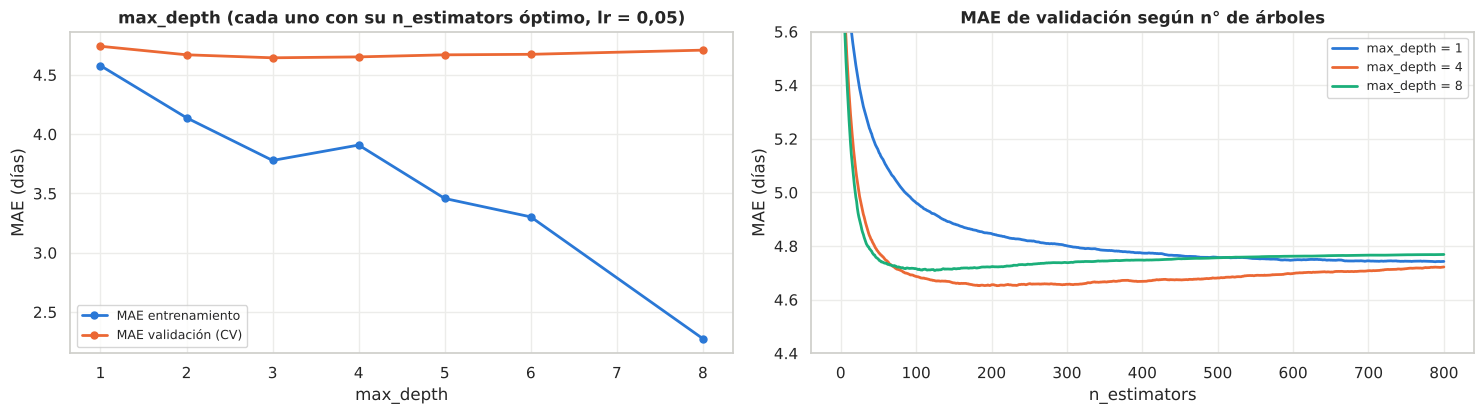

,n_estimators óptimo,MAE train,MAE val,Brecha (val − train)
1,789.0,4.578,4.742,0.163
2,710.0,4.139,4.670,0.531
3,489.0,3.779,4.644,0.866
4,184.0,3.909,4.652,0.743
5,188.0,3.458,4.669,1.211
6,128.0,3.303,4.674,1.371
8,125.0,2.276,4.709,2.433


In [35]:
t0 = time.time()
curvas_depth = {d: curva_gb(dict(learning_rate=0.05, max_depth=d, subsample=0.8)) for d in [1, 2, 3, 4, 5, 6, 8]}
print(f"Curvas de max_depth: {time.time() - t0:.0f} s")
gb_depth = pd.DataFrame({d: {"n_estimators óptimo": c["MAE val"].idxmin(), "MAE train": c.loc[c["MAE val"].idxmin(), "MAE train"],
                             "MAE val": c["MAE val"].min()} for d, c in curvas_depth.items()}).T
gb_depth["Brecha (val − train)"] = gb_depth["MAE val"] - gb_depth["MAE train"]

fig, ax = plt.subplots(1, 2, figsize=(15, 4.3))
grafico_curva(ax[0], gb_depth.index, gb_depth, "max_depth (cada uno con su n_estimators óptimo, lr = 0,05)", "max_depth")
for d, col in zip([1, 4, 8], [AZUL, NARANJO, VERDE]):
    ax[1].plot(curvas_depth[d].index, curvas_depth[d]["MAE val"], color=col, lw=2, label=f"max_depth = {d}")
ax[1].set(title="MAE de validación según n° de árboles", xlabel="n_estimators", ylabel="MAE (días)", ylim=(4.4, 5.6))
ax[1].legend(fontsize=9)
plt.tight_layout(); plt.show()
gb_depth.round(3)

**Interpretación:**
- Con `max_depth` = 1 (árboles de una sola división) el modelo **subajusta**: no puede capturar interacciones (por ejemplo, que la distancia afecta distinto según el estado) y ni con 800 árboles baja de 4,74.
- Al aumentar la profundidad, el error de entrenamiento cae fuerte, pero el de validación mejora solo hasta una profundidad intermedia (3-4: 4,64-4,65). Con `max_depth` = 8 la brecha sube a 2,4 días y la validación empeora (4,71): cada árbol memoriza combinaciones muy específicas (**overfitting**).
- Las profundidades intermedias logran el menor error de validación con una brecha moderada. En la grilla final exploramos 3, 4 y 5, combinadas con `min_samples_leaf` y `subsample`.

In [36]:
t0 = time.time()
grilla_gb = [(d, leaf, ss) for d in [3, 4, 5] for leaf in [1, 20] for ss in [0.8, 1.0]]
curvas_grilla = {g: curva_gb(dict(learning_rate=0.05, max_depth=g[0], min_samples_leaf=g[1], subsample=g[2]), max_arboles=600) for g in grilla_gb}
print(f"Grilla final GB: {time.time() - t0:.0f} s")
res_grilla_gb = pd.DataFrame({g: {"n_estimators óptimo": c["MAE val"].idxmin(), "MAE train": c.loc[c["MAE val"].idxmin(), "MAE train"],
                                  "MAE val": c["MAE val"].min()} for g, c in curvas_grilla.items()}).T
res_grilla_gb.index.names = ["max_depth", "min_samples_leaf", "subsample"]
res_grilla_gb["Brecha (val − train)"] = res_grilla_gb["MAE val"] - res_grilla_gb["MAE train"]
res_grilla_gb.sort_values("MAE val").round(3)

Grilla final GB: 433 s


n_estimators óptimo  MAE train  MAE val  Brecha (val − train)
max_depth min_samples_leaf subsample                                                               
4         20               0.8                      225.0      3.938    4.619                 0.682
                           1.0                      231.0      3.980    4.620                 0.640
3         20               0.8                      404.0      3.999    4.620                 0.622
5         20               1.0                      140.0      3.924    4.626                 0.702
                           0.8                      157.0      3.824    4.627                 0.803
3         20               1.0                      297.0      4.196    4.639                 0.443
          1                0.8                      489.0      3.779    4.644                 0.866
4         1                1.0                      171.0      4.008    4.648                 0.640
                           0.8                      184.0      3.909    4.652                 0.743
3         1                1.0                      283.0      4.147    4.658                 0.511
5         1                1.0                      148.0      3.687    4.658                 0.972
                           0.8                      188.0      3.458    4.669                 1.211

In [37]:
mejor_gb = res_grilla_gb["MAE val"].idxmin()
n_opt = int(res_grilla_gb.loc[mejor_gb, "n_estimators óptimo"])
params_gb = dict(learning_rate=0.05, max_depth=int(mejor_gb[0]), min_samples_leaf=int(mejor_gb[1]), subsample=float(mejor_gb[2]),
                 n_estimators=int(round(n_opt, -1)))
modelo_gb = crear_pipeline(GradientBoostingRegressor(**params_gb, random_state=SEMILLA))
print("Gradient Boosting elegido:", params_gb)
# Verificación con la misma función de CV que los demás modelos
cv_gb = resumen_cv(evaluar_cv(modelo_gb, X_train, y_train))
print(f"CV con n_estimators redondeado: MAE val = {cv_gb['MAE val']:.3f} | MAE train = {cv_gb['MAE train']:.3f}")

Gradient Boosting elegido: {'learning_rate': 0.05, 'max_depth': 4, 'min_samples_leaf': 20, 'subsample': 0.8, 'n_estimators': 220}
CV con n_estimators redondeado: MAE val = 4.622 | MAE train = 3.949


**Elegido: `max_depth` = 4, `min_samples_leaf` = 20, `subsample` = 0,8, `learning_rate` = 0,05 y 220 árboles** (el mínimo de la curva de validación, 225, redondeado a la decena).
- **`min_samples_leaf` = 20 mejora en todas las profundidades** frente a 1: exige que cada hoja tenga al menos 20 órdenes, lo que evita que los árboles aprendan casos puntuales. Es regularización.
- **`subsample`** (0,8 vs. 1,0) casi no cambia el resultado. Mantenemos 0,8 (*stochastic gradient boosting*), porque cada árbol ve un 80% distinto de los datos y queda menos correlacionado con los demás.
- Las primeras cuatro combinaciones quedan a menos de 0,01 días; elegimos la de menor MAE. Su brecha de 0,68 días es moderada.
- La verificación con la misma función de CV que los demás modelos da MAE de validación = 4,622.

### 8.4 Resumen de hiperparámetros

In [38]:
resumen_hp = pd.DataFrame([
    ["Elastic Net", "alpha", ", ".join(map(str, alphas)), "Alto → underfitting; bajo → sin overfitting (modelo lineal con sesgo alto)", alpha_en],
    ["Elastic Net", "l1_ratio", ", ".join(map(str, l1_ratios)), "Efecto menor; Lasso (1.0) deja 54 de 85 coeficientes ≠ 0 (selección de variables)", l1_en],
    ["Random Forest", "max_depth", "2, 4, 6, 8, 10, 14, None", "2-4 → underfitting; sin límite y hojas de 1 → overfitting", "None"],
    ["Random Forest", "min_samples_leaf", "1, 2, 5, 10, 20, 50, 100 (+ grilla 3, 5, 10)", "Principal control del overfitting; 50+ → underfitting", params_rf["min_samples_leaf"]],
    ["Random Forest", "max_features", "0.1, 0.2, 0.33, 0.5, 0.75, 1.0 (+ grilla 0.33, 0.5)", "Muy bajo → underfitting; 1.0 → árboles correlacionados", params_rf["max_features"]],
    ["Random Forest", "n_estimators", "10, 25, 50, 100, 200, 400", "Se estabiliza sobre ~100; no causa overfitting", params_rf["n_estimators"]],
    ["Gradient Boosting", "learning_rate", "0.02, 0.05, 0.1, 0.3", "0.3 → overfitting temprano; 0.02 → necesita muchos árboles", params_gb["learning_rate"]],
    ["Gradient Boosting", "n_estimators", "1 a 800 (curvas)", "Pocos → underfitting; muchos → la validación sube (overfitting)", params_gb["n_estimators"]],
    ["Gradient Boosting", "max_depth", "1, 2, 3, 4, 5, 6, 8", "1 → underfitting (sin interacciones); 8 → overfitting", params_gb["max_depth"]],
    ["Gradient Boosting", "min_samples_leaf", "1, 20", "Regulariza: hojas con más órdenes", params_gb["min_samples_leaf"]],
    ["Gradient Boosting", "subsample", "0.8, 1.0", "Regulariza: cada árbol ve parte de los datos", params_gb["subsample"]],
], columns=["Modelo", "Hiperparámetro", "Valores probados", "Efecto observado", "Valor elegido"])
display(resumen_hp.style.hide(axis="index"))

Modelo,Hiperparámetro,Valores probados,Efecto observado,Valor elegido
Elastic Net,alpha,"0.0005, 0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1.0, 5.0",Alto → underfitting; bajo → sin overfitting (modelo lineal con sesgo alto),0.010000
Elastic Net,l1_ratio,"0.1, 0.5, 0.9, 1.0",Efecto menor; Lasso (1.0) deja 54 de 85 coeficientes ≠ 0 (selección de variables),1.000000
Random Forest,max_depth,"2, 4, 6, 8, 10, 14, None",2-4 → underfitting; sin límite y hojas de 1 → overfitting,None
Random Forest,min_samples_leaf,"1, 2, 5, 10, 20, 50, 100 (+ grilla 3, 5, 10)",Principal control del overfitting; 50+ → underfitting,5
Random Forest,max_features,"0.1, 0.2, 0.33, 0.5, 0.75, 1.0 (+ grilla 0.33, 0.5)",Muy bajo → underfitting; 1.0 → árboles correlacionados,0.330000
Random Forest,n_estimators,"10, 25, 50, 100, 200, 400",Se estabiliza sobre ~100; no causa overfitting,300
Gradient Boosting,learning_rate,"0.02, 0.05, 0.1, 0.3",0.3 → overfitting temprano; 0.02 → necesita muchos árboles,0.050000
Gradient Boosting,n_estimators,1 a 800 (curvas),Pocos → underfitting; muchos → la validación sube (overfitting),220
Gradient Boosting,max_depth,"1, 2, 3, 4, 5, 6, 8",1 → underfitting (sin interacciones); 8 → overfitting,4
Gradient Boosting,min_samples_leaf,"1, 20",Regulariza: hojas con más órdenes,20


## 9. Evaluación en Test, comparación y selección del modelo final

Entrenamos los tres modelos ajustados con **todo Train** (target recortado al percentil 99 de Train) y los evaluamos **una sola vez** en Test, con los valores reales. Además del error, medimos el tiempo de predicción y el tamaño del archivo, porque el modelo se usará en una aplicación web.

In [39]:
(RAIZ / "models").mkdir(exist_ok=True)
X_train_fit, y_train_fit = preparar_target(X_train, y_train, "recorte_p99")
print(f"Percentil 99 de Train (límite del recorte): {y_train.quantile(0.99):.1f} días | órdenes recortadas: {(y_train > y_train.quantile(0.99)).sum()}")

candidatos = {"Elastic Net": modelo_en, "Random Forest": modelo_rf, "Gradient Boosting": modelo_gb}
ajustados, filas, pred_test = {}, [], {}
for nombre, modelo in candidatos.items():
    t = time.time(); m = clone(modelo).fit(X_train_fit, y_train_fit); t_fit = time.time() - t
    t = time.time(); p = m.predict(X_test); t_pred = (time.time() - t) / len(X_test) * 1000
    ruta_tmp = RAIZ / "models" / f"_tmp_{nombre}.joblib"; joblib.dump(m, ruta_tmp); mb = ruta_tmp.stat().st_size / 1e6; ruta_tmp.unlink()
    ajustados[nombre], pred_test[nombre] = m, p
    filas.append({"Modelo": nombre, "MAE train": mean_absolute_error(y_train, m.predict(X_train)), **metricas(y_test, p),
                  "Entrenamiento (s)": t_fit, "Predicción (ms/orden)": t_pred, "Tamaño archivo (MB)": mb})

baseline_media = y_train.mean()
pred_test["Baseline: promedio"] = np.full(len(y_test), baseline_media)
pred_test["Estimación de la plataforma"] = X_test["estimated_delivery_days"].values
filas.append({"Modelo": "Baseline: promedio de Train", "MAE train": mean_absolute_error(y_train, np.full(len(y_train), baseline_media)),
              **metricas(y_test, pred_test["Baseline: promedio"])})
filas.append({"Modelo": "Estimación de la plataforma", "MAE train": mean_absolute_error(y_train, X_train["estimated_delivery_days"]),
              **metricas(y_test, pred_test["Estimación de la plataforma"])})
tabla_test = pd.DataFrame(filas).set_index("Modelo").rename(columns={"MAE": "MAE test"})
tabla_test["Brecha (test − train)"] = tabla_test["MAE test"] - tabla_test["MAE train"]
tabla_test = tabla_test[["MAE train", "MAE test", "Brecha (test − train)", "RMSE", "R2", "Sesgo", "% atraso > 5 días",
                         "Entrenamiento (s)", "Predicción (ms/orden)", "Tamaño archivo (MB)"]]
tabla_test.round(3)

Percentil 99 de Train (límite del recorte): 43.4 días | órdenes recortadas: 55


,MAE train,MAE test,Brecha (test − train),RMSE,R2,Sesgo,% atraso > 5 días,Entrenamiento (s),Predicción (ms/orden),Tamaño archivo (MB)
Modelo,,,,,,,,,,
Elastic Net,4.924,4.893,-0.031,7.217,0.269,-0.212,16.336,0.082,0.008,0.011
Random Forest,3.225,4.531,1.306,6.761,0.359,-0.082,15.820,4.392,0.060,23.923
Gradient Boosting,4.028,4.507,0.479,6.750,0.361,-0.194,16.483,4.664,0.012,0.442
Baseline: promedio de Train,6.155,6.078,-0.077,8.442,-0.000,0.065,19.426,NaN,NaN,NaN
Estimación de la plataforma,12.804,12.514,-0.290,14.750,-2.053,11.350,3.753,NaN,NaN,NaN


### 9.1 Comparación visual

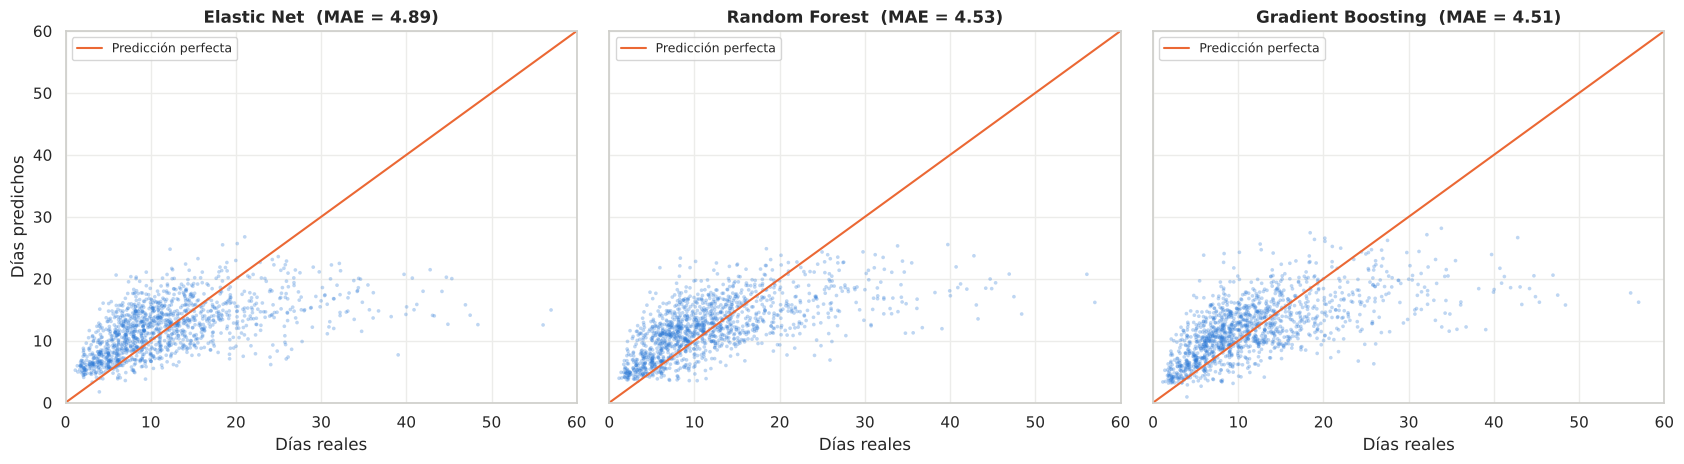

In [40]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8), sharey=True)
for a, nombre in zip(ax, candidatos):
    a.scatter(y_test, pred_test[nombre], s=7, alpha=0.3, color=AZUL, edgecolors="none")
    a.plot([0, 60], [0, 60], color=NARANJO, lw=1.5, label="Predicción perfecta")
    a.set(xlim=(0, 60), ylim=(0, 60), title=f"{nombre}  (MAE = {tabla_test.loc[nombre, 'MAE test']:.2f})", xlabel="Días reales")
    a.legend(loc="upper left", fontsize=9)
ax[0].set_ylabel("Días predichos")
plt.tight_layout(); plt.show()

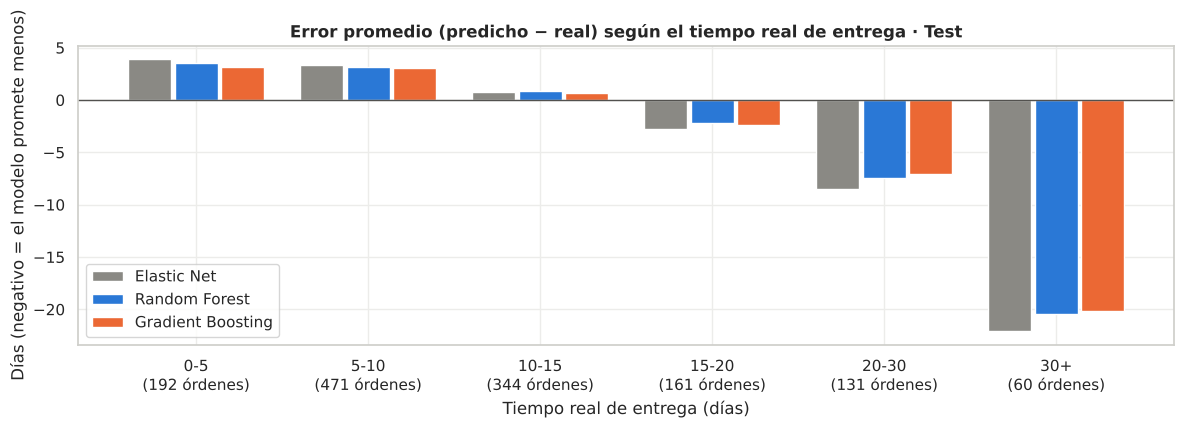

DELIVERY_TIME_DAYS,0-5,5-10,10-15,15-20,20-30,30+
Elastic Net,3.89,3.38,0.75,-2.81,-8.48,-22.07
Random Forest,3.56,3.16,0.83,-2.24,-7.49,-20.44
Gradient Boosting,3.19,3.03,0.64,-2.38,-7.10,-20.16


In [41]:
tramos = pd.cut(y_test, bins=[0, 5, 10, 15, 20, 30, 200], labels=["0-5", "5-10", "10-15", "15-20", "20-30", "30+"])
error_tramo = pd.DataFrame({n: pd.Series(np.asarray(pred_test[n]) - y_test.values, index=y_test.index).groupby(tramos, observed=True).mean()
                            for n in candidatos})
conteo = y_test.groupby(tramos, observed=True).size()
fig, ax = plt.subplots(figsize=(12, 4.3))
ancho = 0.27
xpos = np.arange(len(error_tramo))
for i, (n, col) in enumerate(zip(candidatos, [GRIS, AZUL, NARANJO])):
    ax.bar(xpos + (i - 1) * ancho, error_tramo[n], width=ancho - 0.02, color=col, label=n)
ax.axhline(0, color="#52514e", lw=1)
ax.set_xticks(xpos, [f"{t}\n({c} órdenes)" for t, c in zip(error_tramo.index, conteo)])
ax.set(title="Error promedio (predicho − real) según el tiempo real de entrega · Test", xlabel="Tiempo real de entrega (días)",
       ylabel="Días (negativo = el modelo promete menos)")
ax.legend(); plt.tight_layout(); plt.show()
error_tramo.round(2).T

**Interpretación de los tipos de error:**
- Los tres modelos **sobreestiman los pedidos rápidos** (~3 días en los de 0-10 días) y **subestiman los lentos**: tienden a predecir valores cercanos al centro de la distribución. Es esperable cuando una parte importante de la variación no se puede explicar con la información disponible al comprar (problemas del transportista, clima, huelgas, extravíos).
- El grupo más crítico es el de **más de 30 días** (60 órdenes en Test, 4%): el modelo les promete en promedio ~20 días menos de lo que tardan. En la práctica, esos casos solo se podrían detectar con información posterior a la compra.
- Gradient Boosting tiene el menor error en los tramos extremos (0-5, 20-30 y 30+ días) y Elastic Net el mayor.

### 9.2 Selección del modelo final

In [42]:
criterios = tabla_test.loc[list(candidatos), ["MAE test", "RMSE", "R2", "Sesgo", "% atraso > 5 días", "Brecha (test − train)",
                                              "Predicción (ms/orden)", "Tamaño archivo (MB)"]].copy()
# MAE de validación cruzada obtenido al elegir los hiperparámetros de cada modelo (sección 8)
criterios.insert(0, "MAE CV (Train)", [tabla_en.loc[mejor_en, "MAE val"], res_grilla_rf.loc[(leaf_rf, mf_rf), "MAE val"], cv_gb["MAE val"]])
criterios.round(3)

,MAE CV (Train),MAE test,RMSE,R2,Sesgo,% atraso > 5 días,Brecha (test − train),Predicción (ms/orden),Tamaño archivo (MB)
Modelo,,,,,,,,,
Elastic Net,4.983,4.893,7.217,0.269,-0.212,16.336,-0.031,0.008,0.011
Random Forest,4.694,4.531,6.761,0.359,-0.082,15.820,1.306,0.060,23.923
Gradient Boosting,4.622,4.507,6.750,0.361,-0.194,16.483,0.479,0.012,0.442


**Decisión: Gradient Boosting.** No lo elegimos por una sola métrica, sino porque es el mejor o empata en casi todos los criterios:

| Criterio | Elastic Net | Random Forest | Gradient Boosting | Comentario |
|---|---|---|---|---|
| MAE validación cruzada | 4,98 | 4,69 | **4,62** | El orden se repite en Test: no es suerte del split |
| MAE Test | 4,89 | 4,53 | **4,51** | GB y RF muy cerca (diferencia menor que el error estándar ±0,17) |
| RMSE / R² Test | 7,22 / 0,27 | 6,76 / 0,36 | **6,75 / 0,36** | GB comete menos errores grandes |
| Brecha train-test (MAE) | −0,03 | 1,31 | **0,48** | RF memoriza más Train; GB generaliza mejor |
| Sesgo / % atraso > 5 días | −0,21 / 16,3% | **−0,08 / 15,8%** | −0,19 / 16,5% | RF levemente mejor (~9 órdenes de 1.359) |
| Tamaño del archivo | 0,01 MB | 23,9 MB | **0,44 MB** | RF es 54 veces más pesado para GitHub/Render |
| Interpretabilidad | **Alta** (coeficientes) | Media | Media | Se compensa con la importancia por permutación (§9.4) |

- **Elastic Net** queda descartado: tiene 0,4 días más de error, el peor desempeño en los extremos y alto sesgo estructural (no captura no linealidades).
- **Entre RF y GB**, la diferencia de MAE es pequeña, así que deciden los demás criterios: GB tiene mejor validación cruzada, mejor RMSE y R², una brecha de generalización mucho menor (0,48 vs. 1,31 días) y un archivo 54 veces más liviano, lo que reduce el riesgo en el despliegue.
- **Lo que RF hace mejor:** su sesgo es un poco menor y tiene 0,7 puntos porcentuales menos de atrasos > 5 días. La diferencia es pequeña y no compensa sus desventajas.

In [43]:
NOMBRE_FINAL = "Gradient Boosting"
modelo_final = ajustados[NOMBRE_FINAL]
print("Modelo seleccionado:", NOMBRE_FINAL)
print(modelo_final.named_steps["modelo"])

Modelo seleccionado: Gradient Boosting
GradientBoostingRegressor(learning_rate=0.05, max_depth=4, min_samples_leaf=20,
                          n_estimators=220, random_state=42, subsample=0.8)


### 9.3 Comparación con la estimación actual de la plataforma (visión de negocio)

In [44]:
p_final = pred_test[NOMBRE_FINAL]
plataforma = X_test["estimated_delivery_days"].values
negocio = pd.DataFrame({
    "Estimación de la plataforma": metricas(y_test, plataforma),
    f"Modelo ({NOMBRE_FINAL})": metricas(y_test, p_final),
}).T
negocio["% llega después de lo estimado"] = [100 * np.mean(y_test.values > plataforma), 100 * np.mean(y_test.values > p_final)]
negocio.round(2)

,MAE,RMSE,R2,Sesgo,% atraso > 5 días,% llega después de lo estimado
Estimación de la plataforma,12.51,14.75,-2.05,11.35,3.75,7.80
Modelo (Gradient Boosting),4.51,6.75,0.36,-0.19,16.48,39.37


La plataforma y el modelo cumplen objetivos distintos:
- La **plataforma** promete un plazo "seguro" (muy pocos atrasos), pero se equivoca en promedio por más de 12 días: le dice al cliente que espere el doble de lo necesario, lo que puede desincentivar la compra.
- El **modelo** estima el tiempo **esperado** con un error de 4,5 días y un sesgo casi nulo (−0,2). Por construcción, un 39% de los pedidos llega después del valor puntual, porque es una estimación central y no una promesa. Es menos de la mitad porque la distribución es asimétrica: el promedio queda por encima de la mediana.
- **Uso recomendado:** el modelo entrega la mejor estimación central; para comunicar una **fecha comprometida** al cliente, conviene sumarle un margen. En la sección 10.2 calculamos un **rango probable (80%)** con los errores de la validación cruzada, que es lo que muestra la aplicación web.

### 9.4 ¿Qué variables usa el modelo? (importancia por permutación en Test)

Desordenamos al azar cada entrada, una a la vez, y medimos cuánto empeora el MAE. Si el error sube mucho, el modelo depende de esa variable. Se mide sobre las **entradas originales** (las que ingresa el usuario en la app); por ejemplo, la fecha de compra agrupa el efecto del mes, el día y la hora.

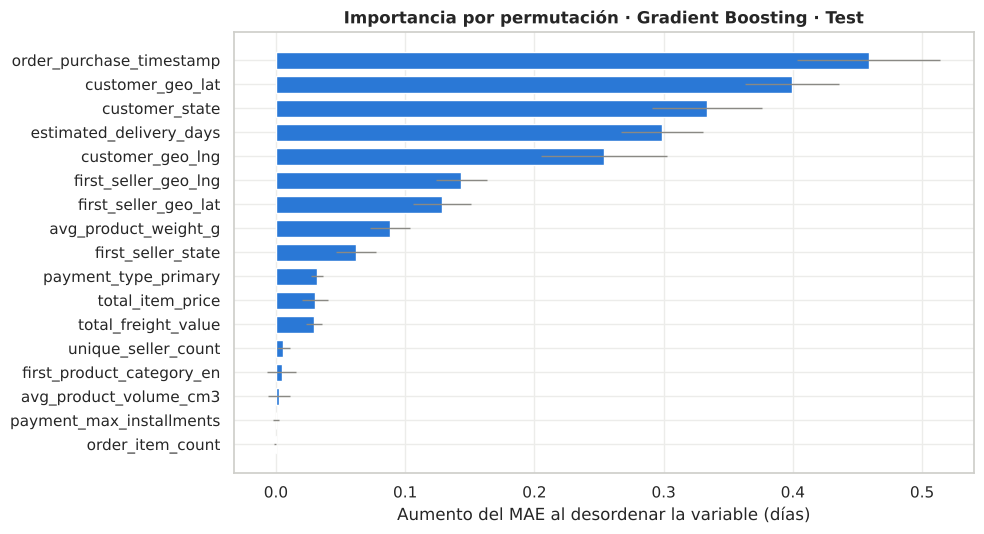

In [45]:
imp = permutation_importance(modelo_final, X_test, y_test, scoring="neg_mean_absolute_error", n_repeats=10, random_state=SEMILLA, n_jobs=-1)
importancia = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(importancia.index, importancia.values, xerr=pd.Series(imp.importances_std, index=X_test.columns)[importancia.index],
        color=AZUL, height=0.7, error_kw=dict(ecolor=GRIS, lw=1))
ax.set(title=f"Importancia por permutación · {NOMBRE_FINAL} · Test", xlabel="Aumento del MAE al desordenar la variable (días)")
plt.tight_layout(); plt.show()

Las variables más importantes son coherentes con el EDA:
- **Fecha de compra:** al desordenarla, el MAE sube ~0,46 días; refleja la estacionalidad y la temporada alta.
- **Ubicación del cliente:** latitud, estado y longitud. Junto con la del vendedor, de ella salen la distancia y el indicador de mismo estado.
- **Estimación de la plataforma** (~0,30 días).
- El **peso**, el estado del vendedor, el medio de pago, el precio y el flete aportan poco.
- La categoría, el volumen, las cuotas y el número de ítems casi nada **una vez que el modelo conoce las demás variables**. Por ejemplo, la información de la categoría ya está en buena parte contenida en el peso y en la ubicación de los vendedores.

### 9.5 Robustez temporal (validación complementaria)

El split principal es aleatorio, así que Train y Test cubren el mismo período. En la práctica el modelo predice **órdenes futuras**. Para medir ese escenario, entrenamos el mismo modelo con el **80% más antiguo** de las órdenes y lo evaluamos con el **20% más reciente**.

In [46]:
orden_t = df[COL_FECHA_COMPRA].sort_values().index
corte = int(len(orden_t) * 0.8)
idx_pasado, idx_futuro = orden_t[:corte], orden_t[corte:]
print(f"Entrenamiento: {df.loc[idx_pasado, COL_FECHA_COMPRA].min():%Y-%m-%d} a {df.loc[idx_pasado, COL_FECHA_COMPRA].max():%Y-%m-%d}"
      f" | Evaluación: {df.loc[idx_futuro, COL_FECHA_COMPRA].min():%Y-%m-%d} a {df.loc[idx_futuro, COL_FECHA_COMPRA].max():%Y-%m-%d}")
m_temp = clone(candidatos[NOMBRE_FINAL]).fit(*preparar_target(X.loc[idx_pasado], y.loc[idx_pasado], "recorte_p99"))
p_temp = m_temp.predict(X.loc[idx_futuro])
temporal = pd.DataFrame({
    "Split aleatorio (Test principal)": metricas(y_test, p_final),
    "Split temporal: futuro": metricas(y.loc[idx_futuro], p_temp),
    "Baseline temporal (promedio del pasado)": metricas(y.loc[idx_futuro], np.full(len(idx_futuro), y.loc[idx_pasado].mean())),
}).T
temporal["Tiempo real promedio"] = [y_test.mean(), y.loc[idx_futuro].mean(), y.loc[idx_futuro].mean()]
temporal["Predicción promedio"] = [p_final.mean(), p_temp.mean(), y.loc[idx_pasado].mean()]
temporal.round(2)

Entrenamiento: 2016-09-15 a 2018-05-26 | Evaluación: 2018-05-26 a 2018-08-28


,MAE,RMSE,R2,Sesgo,% atraso > 5 días,Tiempo real promedio,Predicción promedio
Split aleatorio (Test principal),4.51,6.75,0.36,-0.19,16.48,12.22,12.02
Split temporal: futuro,4.01,5.36,-0.05,2.33,5.00,8.43,10.76
Baseline temporal (promedio del pasado),6.08,7.10,-0.84,4.80,4.27,8.43,13.23


**Interpretación:**
- El modelo se entrenó con órdenes hasta el 26-05-2018 y se evaluó con las del 26-05 al 28-08-2018. En ese período los pedidos fueron mucho más rápidos (8,4 días en promedio vs. 12,2 en el Test aleatorio, §4.3).
- El MAE (4,01) es *menor* que en el Test principal, porque los tiempos son más cortos y menos dispersos. Lo importante es el **sesgo: +2,33 días**. El modelo predice 10,8 días en promedio cuando el real es 8,4: aprendió una logística más lenta que la actual.
- El R² cae a −0,05. Hay que interpretarlo con cuidado: el R² compara contra el promedio *del propio período evaluado* (8,4 días), que en la práctica no se conoce de antemano, y el sesgo de +2,3 días basta para anular la ventaja.
- Frente a lo que sí se conoce al predecir, el promedio histórico (MAE 6,08, sesgo +4,8), **el modelo reduce el error en 34%**. La relación entre las variables y el tiempo de entrega se mantiene; lo que cambia es el **nivel general**.
- **Implicancia práctica:** el modelo debe **reentrenarse periódicamente** con las órdenes más recientes (por ejemplo, cada mes con una ventana móvil) y su sesgo debe monitorearse en producción. Es una limitación que declaramos en las conclusiones.

## 10. K-Fold Cross Validation (K = 5) del modelo seleccionado

Aplicamos K-Fold con K = 5 **solo sobre Train**, con la configuración final y el mismo procedimiento de entrenamiento (recorte del target en cada fold). Reportamos todas las métricas por fold, su promedio y su desviación estándar, y comparamos con Test.

In [47]:
folds_final, oof = evaluar_cv(candidatos[NOMBRE_FINAL], X_train, y_train, devolver_predicciones=True)
COLS_KF = ["MAE train", "MAE", "RMSE", "R2", "Sesgo", "% atraso > 5 días"]
por_fold = folds_final.set_index("Fold")[COLS_KF]
por_fold.index = [f"Fold {i}" for i in por_fold.index]
fila_test = {"MAE train": tabla_test.loc[NOMBRE_FINAL, "MAE train"], **metricas(y_test, p_final)}
resumen_kf = pd.DataFrame({
    "Promedio CV": por_fold.mean(),
    "Desv. estándar CV": por_fold.std(),
    "Coef. variación CV (%)": 100 * por_fold.std() / por_fold.mean().abs(),
    "Test (sección 9)": pd.Series(fila_test)[COLS_KF],
}).T
tabla_kfold = pd.concat([por_fold, resumen_kf])
tabla_kfold.round(3)

,MAE train,MAE,RMSE,R2,Sesgo,% atraso > 5 días
Fold 1,3.938,4.669,7.863,0.274,-0.225,15.087
Fold 2,3.952,4.652,7.071,0.328,-0.144,15.823
Fold 3,3.926,4.598,6.977,0.343,-0.086,15.285
Fold 4,3.975,4.594,6.686,0.372,-0.158,16.206
Fold 5,3.955,4.595,8.093,0.276,-0.124,14.917
Promedio CV,3.949,4.622,7.338,0.319,-0.147,15.464
Desv. estándar CV,0.019,0.036,0.607,0.043,0.051,0.537
Coef. variación CV (%),0.477,0.779,8.267,13.527,34.736,3.472
Test (sección 9),4.028,4.507,6.750,0.361,-0.194,16.483


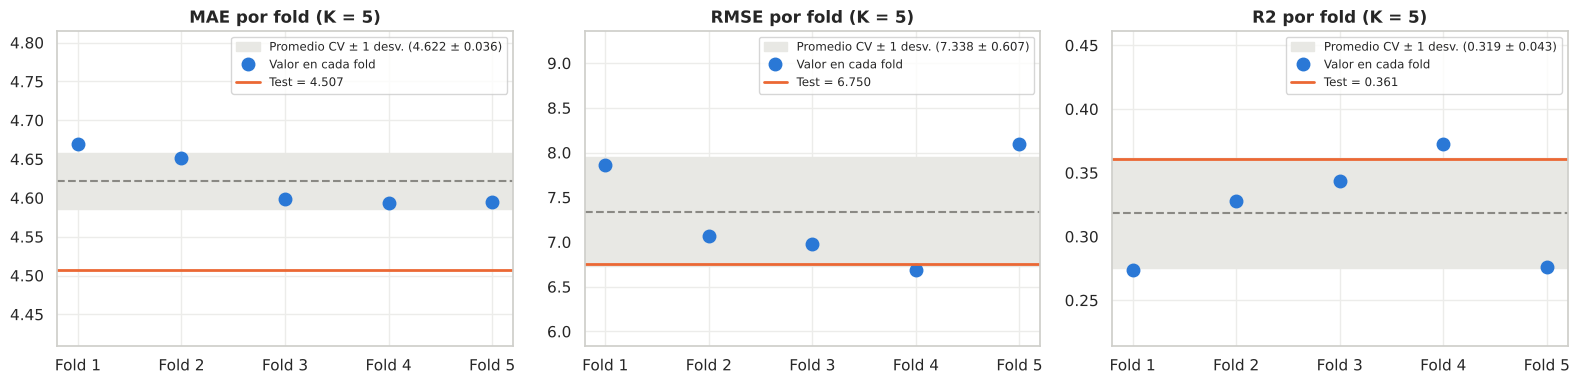

In [48]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, met in zip(ax, ["MAE", "RMSE", "R2"]):
    vals = por_fold[met]
    v_test = resumen_kf.loc["Test (sección 9)", met]
    media, desv = vals.mean(), vals.std()
    a.axhspan(media - desv, media + desv, color="#e8e8e4", label=f"Promedio CV ± 1 desv. ({media:.3f} ± {desv:.3f})")
    a.axhline(media, color=GRIS, ls="--", lw=1.5)
    a.plot(vals.index, vals.values, "o", ms=9, color=AZUL, label="Valor en cada fold")
    a.axhline(v_test, color=NARANJO, lw=2, label=f"Test = {v_test:.3f}")
    rango = max(vals.max(), v_test) - min(vals.min(), v_test)
    a.set(title=f"{met} por fold (K = 5)", ylim=(min(vals.min(), v_test) - 0.6 * rango, max(vals.max(), v_test) + 0.9 * rango))
    a.legend(fontsize=8.5, loc="upper right")
plt.tight_layout(); plt.show()

**Interpretación:**
- **Estabilidad:** el MAE va de 4,59 a 4,67 entre folds (promedio 4,622, desviación 0,036, coeficiente de variación 0,8%). El desempeño **no depende de qué órdenes caen en cada fold**: el modelo es estable.
- **RMSE y R² varían más** (RMSE de 6,69 a 8,09; R² de 0,27 a 0,37). Los folds 1 y 5 contienen más pedidos extremos, y el RMSE, al elevar los errores al cuadrado, es sensible a unos pocos casos de 60-167 días. Es coherente con la cola larga del target (§4.1) y es una razón más para usar el MAE como métrica principal.
- **Overfitting controlado:** el MAE de entrenamiento (3,95) es menor que el de validación (4,62), con una brecha de 0,67 días que se mantiene igual en los 5 folds.
- **Sesgo:** pequeño y negativo en todos los folds (−0,09 a −0,23 días).
- **Comparación con Test:** el MAE de Test (4,51) es 0,11 días mejor que el promedio de CV. Hay tres razones:
  1. El modelo evaluado en Test se entrenó con el 100% de Train (5.432 órdenes), y cada fold con el 80% (~4.350); más datos dan un modelo algo mejor.
  2. Test tiene menos casos extremos (máximo 86,9 días vs. 167,6 en Train). Por eso su RMSE (6,75) es menor y su R² (0,36) mayor que en CV.
  3. La diferencia está dentro del error estándar del MAE de Test (±0,17 días).
- **Conclusión:** no hay señales de que el resultado de Test sea suerte del split ni de que hayamos sobreajustado a la validación. Una estimación honesta del error del modelo en órdenes nuevas del mismo período es **4,5-4,6 días de MAE**.

### 10.2 Rango probable de la predicción (usado en la app)

Una predicción puntual no dice cuán segura es. Con las predicciones **fuera de fold** de la validación cruzada (cada orden de Train predicha por un modelo que no la vio), calculamos la razón *real / predicho*. Sus percentiles 10 y 90 definen un rango que, según la validación, debería contener al 80% de los pedidos. Usamos una razón (y no una diferencia) porque el error crece con el plazo: un pedido estimado en 20 días tiene más incertidumbre que uno de 5.

Verificamos en Test, que no se usó para calcularlo, si el rango efectivamente cubre ~80% de los pedidos.

In [49]:
razon = y_train / oof
q_inf, q_sup = razon.quantile(0.10), razon.quantile(0.90)
cobertura_cv = np.mean((y_train >= oof * q_inf) & (y_train <= oof * q_sup))
cobertura_test = np.mean((y_test.values >= p_final * q_inf) & (y_test.values <= p_final * q_sup))
print(f"Rango probable = [predicción × {q_inf:.3f} ; predicción × {q_sup:.3f}]")
print(f"Cobertura en Train (CV): {cobertura_cv:.1%} | Cobertura en Test: {cobertura_test:.1%}")
print(f"Ejemplo: si el modelo predice 10 días, el rango probable es {10*q_inf:.1f} a {10*q_sup:.1f} días")

Rango probable = [predicción × 0.491 ; predicción × 1.657]
Cobertura en Train (CV): 80.0% | Cobertura en Test: 80.7%
Ejemplo: si el modelo predice 10 días, el rango probable es 4.9 a 16.6 días


## 11. Exportación del modelo para la aplicación web

Guardamos el **Pipeline completo** (variables derivadas + imputación + escalamiento + dummies + modelo) en un solo archivo con `joblib`. La aplicación carga ese archivo y llama a `predict` con los datos del formulario, de modo que el preprocesamiento es **exactamente** el mismo del análisis.

El modelo exportado es **el mismo que se evaluó en Test** (entrenado con Train). También guardamos un archivo de metadatos con las métricas, los hiperparámetros, el rango probable y las listas de valores válidos para el formulario, y una tabla de ciudades con sus coordenadas para que el usuario elija una ciudad en vez de escribir latitud y longitud.

In [50]:
CARPETA_MODELOS = RAIZ / "models"
CARPETA_MODELOS.mkdir(exist_ok=True)
joblib.dump(modelo_final, CARPETA_MODELOS / "modelo_final.joblib", compress=3)

# Tabla de ciudades -> coordenadas (mediana de las coordenadas observadas por ciudad), para clientes y vendedores
coords = pd.concat([
    df_raw[["customer_state", "customer_city", "customer_geo_lat", "customer_geo_lng"]].set_axis(["estado", "ciudad", "lat", "lng"], axis=1),
    df_raw[["first_seller_state", "first_seller_city", "first_seller_geo_lat", "first_seller_geo_lng"]].set_axis(["estado", "ciudad", "lat", "lng"], axis=1),
]).dropna()
ciudades = coords.groupby(["estado", "ciudad"], as_index=False).agg(lat=("lat", "median"), lng=("lng", "median"), ordenes=("lat", "size"))
ciudades[["lat", "lng"]] = ciudades[["lat", "lng"]].round(4)
ciudades.to_csv(RAIZ / "data" / "ciudades.csv", index=False)

params_finales = modelo_final.named_steps["modelo"].get_params()
ejemplo = X_test.iloc[[0]].copy()
metadata = {
    "modelo": NOMBRE_FINAL,
    "hiperparametros": {k: params_finales[k] for k in ["n_estimators", "learning_rate", "max_depth", "min_samples_leaf", "subsample"] if k in params_finales},
    "version_sklearn": sklearn.__version__,
    "entrenado_con": f"Train ({len(X_train)} órdenes), target recortado al percentil 99 ({y_train.quantile(0.99):.1f} días)",
    "metricas_test": {k: round(float(v), 4) for k, v in metricas(y_test, p_final).items()},
    "metricas_cv": {k: round(float(resumen_kf.loc["Promedio CV", k]), 4) for k in ["MAE", "RMSE", "R2", "Sesgo"]},
    "mae_plataforma_test": round(float(mean_absolute_error(y_test, plataforma)), 4),
    "rango_probable": {"q_inf": round(float(q_inf), 4), "q_sup": round(float(q_sup), 4), "cobertura_test": round(float(cobertura_test), 4)},
    "entradas": ENTRADAS,
    "categorias": {c: sorted(X_train[c].dropna().astype(str).unique().tolist()) for c in ENTRADAS_CATEGORICAS},
    "rangos_train": {c: [float(X_train[c].min()), float(X_train[c].max())] for c in ENTRADAS_NUMERICAS},
    "ejemplo": json.loads(ejemplo.assign(**{COL_FECHA_COMPRA: ejemplo[COL_FECHA_COMPRA].dt.strftime("%Y-%m-%dT%H:%M")}).iloc[0].to_json()),
    "ejemplo_real_dias": round(float(y_test.iloc[0]), 2),
}
with open(CARPETA_MODELOS / "metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

# Prueba: cargar el archivo como lo hará la app y predecir
cargado = joblib.load(CARPETA_MODELOS / "modelo_final.joblib")
assert np.allclose(cargado.predict(X_test), p_final)
print(f"modelo_final.joblib: {(CARPETA_MODELOS / 'modelo_final.joblib').stat().st_size / 1e6:.2f} MB | ciudades: {len(ciudades)}")
print(f"Predicción del ejemplo: {cargado.predict(ejemplo)[0]:.2f} días (real: {y_test.iloc[0]:.2f} días)")

modelo_final.joblib: 0.15 MB | ciudades: 1460
Predicción del ejemplo: 14.72 días (real: 9.06 días)


## 12. Conclusiones

**Principales hallazgos**
1. **El problema y los datos:** cada fila es una orden. De las 7.000 órdenes, 6.791 tienen target (fueron entregadas). El tiempo de entrega promedio es de 12,3 días, con una cola larga de hasta 167 días.
2. **Dimensión crítica: fuga de información.** Unas 15 columnas solo se conocen después de la compra (despacho, atraso respecto de lo estimado, reseñas, estado de la orden). Con ellas, el R² sube a 0,92, un resultado falso e inutilizable. Las identificamos con un criterio explícito (¿se conoce al comprar?), lo verificamos con datos y entrenamos solo con información disponible al comprar.
3. **Modelo final: Gradient Boosting**, con MAE de 4,51 días en Test y 4,62 ± 0,04 en K-Fold. Reduce el error en 26% frente al baseline (6,08) y en 64% frente a la estimación actual de la plataforma (12,5), con un sesgo casi nulo.
4. **Qué determina el tiempo de entrega:** la temporada de compra, la ubicación del cliente y del vendedor (distancia, mismo estado) y el plazo que informa la plataforma.
5. **Atípicos del target:** recortarlos al percentil 99 solo en el entrenamiento dio el mejor equilibrio. Eliminar atípicos o usar logaritmo bajaba el MAE, pero el modelo prometía menos días de los reales (sesgo de −1,1 a −1,2 días).

**Limitaciones**
- **R² de 0,36:** la mayor parte de la variación depende de eventos posteriores a la compra (transportista, clima, huelgas, extravíos), que no se pueden anticipar con estos datos. Los pedidos de más de 30 días se subestiman en ~20 días.
- **Drift temporal:** los datos son de 2016-2018 y la logística mejoró durante el período. Entrenado con el pasado, el modelo sobreestimó en 2,3 días el período más reciente, así que **debe reentrenarse periódicamente**. Usarlo en 2026 supone que los patrones relativos se mantienen.
- Cada orden se representa por su primer producto y su primer vendedor. En la app, la ubicación se aproxima por ciudad o por estado.
- El rango probable (80%) se calculó empíricamente y supone que la distribución de errores futura es parecida a la histórica (cobertura en Test: 80,7%).

**Aprendizajes**
- Un R² muy alto puede ser señal de fuga, no de un buen modelo. La pregunta clave es: *¿esta variable existe en el momento en que voy a predecir?*
- La métrica debe reflejar el costo del negocio. Por eso, además del MAE, medimos el sesgo y los atrasos, que llevaron a descartar alternativas con menor MAE.
- Los hiperparámetros que controlan la complejidad (`min_samples_leaf`, `max_depth`, `learning_rate` × `n_estimators`) permiten ubicarse entre el underfitting y el overfitting; las curvas de entrenamiento vs. validación lo hacen visible.
- Encapsular todo el preprocesamiento en un `Pipeline` evita filtrar información de Test y garantiza que la aplicación web use exactamente la misma transformación que el análisis.

**Próximos pasos:**
- Un modelo de cuantiles para comunicar una fecha comprometida, por ejemplo el percentil 80.
- Modelos de re-estimación en etapas posteriores (cuando el vendedor despacha), donde las variables del proceso sí serían legítimas.
- Reentrenamiento automático con datos recientes.